# Predicting Booking Cancellations at Reservation Time
### A temporal validation study with leakage control on hotel demand data

## Part 1: Getting the data, cleaning it and exploring it

**Course:** Data Science Tools and Technologies | **Instructor:** Dr. Asma Ahmed | **TA:** Burhan Hadi Butt

**Team:** Nurmeen Shahid (26L-8010) and Ayesha Mazher (26L-8005)

### Research question
Can the information a hotel has at the moment of booking tell us which reservations are likely to be cancelled?

This repository contains the full project: **Part 1** (data preparation, leakage audit, EDA) and **Part 2** (model training, tuning, evaluation, cost analysis and the final scoring pipeline).

This first half of the project goes from getting the data to exploring it. We do not train or test any model here. We set out to do six things:

1. Download the data and check that its structure is what we expect.
2. Deal with missing values, duplicates, outliers and invalid records.
3. Sort every column by when its value becomes known (the leakage audit).
4. Build new features and define three feature sets for Part 2.
5. Set up a time-based split that keeps 2017 untouched as the test period.
6. Describe the cancellation patterns, always showing sample sizes and 95% confidence intervals.

In [1]:
# Install kagglehub. We use it to download the dataset from Kaggle.
%pip install kagglehub

In [2]:
# Libraries we need.
# numpy and pandas are for data work. seaborn and matplotlib are for charts.
import warnings
import numpy as np
import pandas as pd
import kagglehub
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from pathlib import Path
# chi2_contingency is used later for Cramer's V.
from scipy.stats import chi2_contingency

# Hide warning messages, so the output stays clean.
warnings.filterwarnings("ignore")
# One common look for all charts.
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (8, 4)
pd.set_option("display.max_colwidth", None)

# Fixed seed. We get the same results every time we run.
RANDOM_STATE = 42

In [3]:
# Helper 1: confidence interval for a rate (like cancellation rate).
# Wilson method is better than the simple method when the group is small.
def wilson_interval(successes, total, z=1.96):
    """Approximate 95% Wilson confidence interval for a proportion."""
    # p is the observed rate. For example 0.37 means 37%.
    p = successes / total
    # These three lines are the Wilson formula. z = 1.96 gives a 95% interval.
    denominator = 1 + z**2 / total
    center = (p + z**2 / (2 * total)) / denominator
    margin = z * np.sqrt(p * (1 - p) / total + z**2 / (4 * total**2)) / denominator
    # Lower end and upper end of the interval.
    return center - margin, center + margin

In [4]:
# Helper 2: makes a summary table for any column.
# It gives bookings, cancellations, cancellation rate and 95% CI for each group.
def cancellation_summary(data, group_column, min_bookings=1, sort=True):
    """Bookings, cancellations, cancellation rate and 95% CI for each group."""
    # Count the bookings and the cancellations in each group.
    result = (
        data.groupby(group_column, observed=True)["is_canceled"]
        .agg(bookings="size", cancellations="sum")
        .reset_index()
    )
    # Rate = cancellations divided by bookings.
    result["cancellation_rate"] = result["cancellations"] / result["bookings"]
    # Add the confidence interval for each group.
    result["ci_low"], result["ci_high"] = wilson_interval(result["cancellations"], result["bookings"])
    # Remove very small groups. Their rates are not reliable.
    result = result[result["bookings"] >= min_bookings]
    # Show the highest rate first (when sort is True).
    if sort:
        result = result.sort_values("cancellation_rate", ascending=False)
    return result.reset_index(drop=True)

In [5]:
# Helper 3: bar chart of cancellation rate with error bars (95% CI).
# The sample size (n) is written in every label.
def plot_rates(summary, column, title):
    """Horizontal bars of cancellation rate with 95% CI; sample size is shown in each label."""
    # Label for each bar. Example: City Hotel (n=79,330).
    labels = [f"{value} (n={n:,})" for value, n in zip(summary[column], summary["bookings"])]
    rate = summary["cancellation_rate"]
    # Make the chart taller when there are more bars.
    plt.figure(figsize=(8, max(3, 0.5 * len(summary) + 1)))
    # Draw the bars.
    plt.barh(range(len(summary)), rate, color="steelblue")
    # Draw the confidence interval as black lines on the bars.
    plt.errorbar(rate, range(len(summary)),
                 xerr=[rate - summary["ci_low"], summary["ci_high"] - rate],
                 fmt="none", color="black", capsize=3)
    # Put the labels on the left side.
    plt.yticks(range(len(summary)), labels)
    # Keep the first row on top.
    plt.gca().invert_yaxis()
    # Rate is always between 0 and 1, so we fix the x axis.
    plt.xlim(0, 1)
    plt.xlabel("Cancellation rate")
    plt.title(title)
    plt.tight_layout()
    plt.show()

## 2. Dataset Loading

**Source.** We use the Hotel Booking Demand dataset from Kaggle (`jessemostipak/hotel-booking-demand`). It was first published by Antonio, Almeida and Nunes (2019) in *Data in Brief*, 22, 41–49. Each row is one booking at either a city hotel or a resort hotel in Portugal.

**Loading notes.** The CSV writes missing values as the text `NULL`, so we pass `na_values=["NULL"]` to turn them into real missing values. We keep the untouched data in `df_raw` and do all the cleaning on a copy called `df`. The data has no booking ID or guest ID.

In [6]:
# Downloading the latest version

# Download the dataset from Kaggle. It is saved in a local cache folder.
path = kagglehub.dataset_download("jessemostipak/hotel-booking-demand")
print("Path to dataset files:", path)

# 'NULL' strings in this CSV are missing values
# Read the CSV file. The text NULL is changed to a real missing value.
df_raw = pd.read_csv(Path(path) / "hotel_bookings.csv", na_values=["NULL"])

# Quick safety checks. If the data is not what we expect, the code stops here.
assert df_raw.shape == (119390, 32)
assert set(df_raw["is_canceled"].unique()) == {0, 1}
# Show the size of the data.
print("Rows:", f"{df_raw.shape[0]:,}", "| Columns:", df_raw.shape[1])
# Look at the first 5 rows.
df_raw.head()

Using Colab cache for faster access to the 'hotel-booking-demand' dataset.
Path to dataset files: /kaggle/input/hotel-booking-demand
Rows: 119,390 | Columns: 32


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


## 3. Initial Data Exploration

### 3.1 Structure and summary statistics

Before changing anything, we look at the data types and distributions. This tells us how each column should be handled.

In [7]:
# Column names, data types and missing values in one view.
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal            

In [8]:
# Summary statistics (mean, min, max) for number columns. .T makes it easy to read.
display(df_raw.describe().T)

,count,mean,std,min,25%,50%,75%,max
is_canceled,119390.0,0.370416,0.482918,0.00,0.00,0.000,1.0,1.0
lead_time,119390.0,104.011416,106.863097,0.00,18.00,69.000,160.0,737.0
arrival_date_year,119390.0,2016.156554,0.707476,2015.00,2016.00,2016.000,2017.0,2017.0
arrival_date_week_number,119390.0,27.165173,13.605138,1.00,16.00,28.000,38.0,53.0
arrival_date_day_of_month,119390.0,15.798241,8.780829,1.00,8.00,16.000,23.0,31.0
stays_in_weekend_nights,119390.0,0.927599,0.998613,0.00,0.00,1.000,2.0,19.0
stays_in_week_nights,119390.0,2.500302,1.908286,0.00,1.00,2.000,3.0,50.0
adults,119390.0,1.856403,0.579261,0.00,2.00,2.000,2.0,55.0
children,119386.0,0.103890,0.398561,0.00,0.00,0.000,0.0,10.0
babies,119390.0,0.007949,0.097436,0.00,0.00,0.000,0.0,10.0


In [9]:
# Summary for text columns: unique values and the most common value.
display(df_raw.describe(include="object").T)

,count,unique,top,freq
hotel,119390,2,City Hotel,79330
arrival_date_month,119390,12,August,13877
meal,119390,5,BB,92310
country,118902,177,PRT,48590
market_segment,119390,8,Online TA,56477
distribution_channel,119390,5,TA/TO,97870
reserved_room_type,119390,10,A,85994
assigned_room_type,119390,12,A,74053
deposit_type,119390,3,No Deposit,104641
customer_type,119390,4,Transient,89613


**What we noticed**
- There are 119,390 rows and 32 columns: 16 integer, 4 float and 12 text columns.
- `lead_time` is right-skewed (mean 104 days, median 69, maximum 737).
- `adr` goes from −6.38 up to 5,400, so some values are invalid or extreme. We deal with them in 4.3.
- `agent` and `company` are ID numbers, so we treat them as categories and not as quantities.

### 3.2 Dates and the chronological split

We rebuild the arrival date from the year, month and day columns. The split follows our proposal: arrivals in 2015–2016 are the train/validation period, and all 2017 arrivals are the test period.

In [10]:
# Work on a copy. The original data stays safe in df_raw.
df = df_raw.copy()   # df_raw stays untouched; all cleaning is done on df

# Months in the correct order. We need this for sorting and for making dates.
month_order = ["January", "February", "March", "April", "May", "June", "July",
               "August", "September", "October", "November", "December"]
# Dictionary to change month name into number (January becomes 1).
month_number = {month: number for number, month in enumerate(month_order, start=1)}

# Join year, month and day to make one real date column.
df["arrival_date"] = pd.to_datetime(dict(
    year=df["arrival_date_year"],
    month=df["arrival_date_month"].map(month_number),
    day=df["arrival_date_day_of_month"],
))

# Time-based split. 2015-2016 is for training. 2017 is for the test.
# We do not use a random split, because in real life we predict the future.
# Chronological split from the proposal: train/validation = 2015-2016, test = 2017
df["split"] = np.where(df["arrival_date_year"] < 2017, "train_val", "test")

# Check the date range and how many rows are in each part.
print("Arrival dates:", df["arrival_date"].min().date(), "to", df["arrival_date"].max().date())
print(df["split"].value_counts())
print("\nBookings by arrival month and year:")
# Table of bookings by month and year. It shows that months are not covered equally.
display(pd.crosstab(df["arrival_date_month"], df["arrival_date_year"]).reindex(month_order))

Arrival dates: 2015-07-01 to 2017-08-31
split
train_val    78703
test         40687
Name: count, dtype: int64

Bookings by arrival month and year:


arrival_date_year,2015,2016,2017
arrival_date_month,,,
January,0,2248,3681
February,0,3891,4177
March,0,4824,4970
April,0,5428,5661
May,0,5478,6313
June,0,5292,5647
July,2776,4572,5313
August,3889,5063,4925
September,5114,5394,0


**What we found**
- Arrivals run from 1 July 2015 to 31 August 2017.
- The calendar months are not covered equally. July and August appear in three years, January to June in two (2016 and 2017), and September to December in two (2015 and 2016). If we pool the months, July and August look bigger than they really are, so monthly patterns have to be read year by year.
- The split gives 78,703 bookings for train/validation and 40,687 for the test. The test period only covers January to August, so we will compare test months with the same months of 2016.

### 3.3 Variable groups
The 32 columns fall into eight groups, counting the target and the outcome columns (definitions follow Antonio et al., 2019).

| Group | Columns | What they describe |
|---|---|---|
| Target | `is_canceled` | 1 = cancelled or no-show, 0 = checked out |
| Booking and timing | `hotel`, `lead_time`, `arrival_date_*` (4 columns) | Which hotel, days booked ahead, arrival date |
| Stay and guests | `stays_in_week_nights`, `stays_in_weekend_nights`, `adults`, `children`, `babies`, `meal` | Length of stay, party size, meal package |
| Guest and channel | `country`, `market_segment`, `distribution_channel`, `customer_type`, `agent`, `company` | Where the booking came from |
| History | `is_repeated_guest`, `previous_cancellations`, `previous_bookings_not_canceled` | The guest's earlier bookings |
| Price and policy | `adr`, `deposit_type`, `days_in_waiting_list` | Daily rate, deposit rule, waiting time |
| Room and requests | `reserved_room_type`, `assigned_room_type`, `booking_changes`, `required_car_parking_spaces`, `total_of_special_requests` | Room and extras |
| Outcome (excluded) | `reservation_status`, `reservation_status_date` | Final status. It gives away the target, so we drop it in Section 7 |

In [11]:
# Schema table: data type, unique values, missing count and one example for each column.
schema = pd.DataFrame({
    "dtype": df_raw.dtypes.astype(str),
    "unique": df_raw.nunique(),
    "missing": df_raw.isna().sum(),
    "example": df_raw.iloc[0],
})
display(schema)

,dtype,unique,missing,example
hotel,object,2,0,Resort Hotel
is_canceled,int64,2,0,0
lead_time,int64,479,0,342
arrival_date_year,int64,3,0,2015
arrival_date_month,object,12,0,July
arrival_date_week_number,int64,53,0,27
arrival_date_day_of_month,int64,31,0,1
stays_in_weekend_nights,int64,17,0,0
stays_in_week_nights,int64,35,0,0
adults,int64,14,0,2


### 3.4 Distributions and cardinality
Here we look at skewness, columns that are mostly zeros, and how many categories each column has. These decide which transformations and encodings we need in Part 2.

,median,skew,zeros_%,max
babies,0.00,24.65,99.23,10.0
days_in_waiting_list,0.00,11.94,96.90,391.0
previous_cancellations,0.00,24.46,94.57,26.0
required_car_parking_spaces,0.00,4.16,93.79,8.0
children,0.00,4.11,92.80,10.0
booking_changes,0.00,6.00,84.86,21.0
total_of_special_requests,0.00,1.35,58.90,5.0
stays_in_weekend_nights,1.00,1.38,43.55,19.0
stays_in_week_nights,2.00,2.86,6.40,50.0
lead_time,69.00,1.35,5.31,737.0


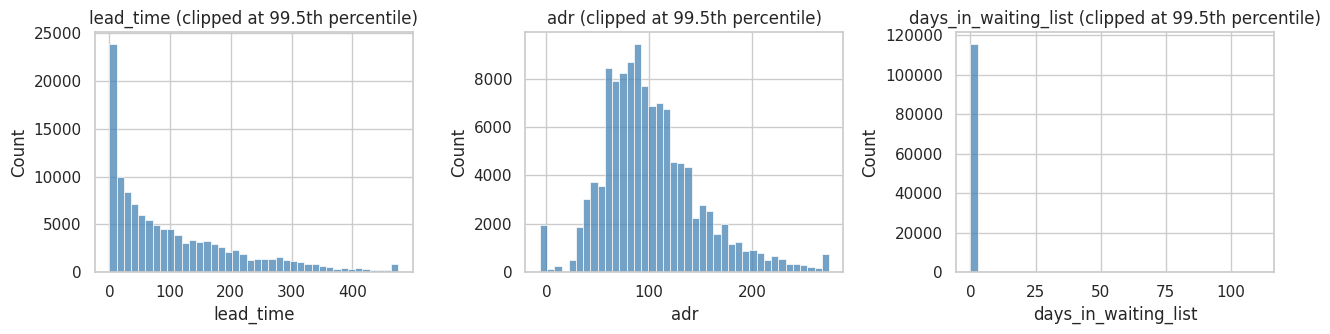

Distinct values: {'country': 177, 'agent': 333, 'company': 352, 'market_segment': 8, 'reserved_room_type': 10}


In [12]:
# Number columns we want to profile.
num_cols = ["lead_time", "adr", "stays_in_week_nights", "stays_in_weekend_nights", "adults",
            "children", "babies", "previous_cancellations", "booking_changes",
            "days_in_waiting_list", "required_car_parking_spaces", "total_of_special_requests"]

# Median, skewness, percent of zeros and max for each column.
# High skew means a long tail on the right side.
profile = pd.DataFrame({
    "median": df_raw[num_cols].median(),
    "skew": df_raw[num_cols].skew(),
    "zeros_%": (df_raw[num_cols] == 0).mean() * 100,
    "max": df_raw[num_cols].max(),
}).round(2)
# Show the columns with the most zeros first.
display(profile.sort_values("zeros_%", ascending=False))

# Only the three fields where the shape drives a Phase 2 decision
# Histograms of three important columns.
# We clip at the 99.5th percentile, so extreme values do not squash the chart.
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, c in zip(axes, ["lead_time", "adr", "days_in_waiting_list"]):
    s = df_raw[c]
    sns.histplot(s.clip(upper=s.quantile(0.995)), bins=40, ax=ax, color="steelblue")
    ax.set_title(f"{c} (clipped at 99.5th percentile)")
plt.tight_layout(); plt.show()

# How many different values the high-cardinality columns have.
print("Distinct values:", df_raw[["country", "agent", "company", "market_segment", "reserved_room_type"]].nunique().to_dict())

**What we noticed**
- **Mostly zeros:** `babies` (99.2% zeros), `days_in_waiting_list` (96.9%), `previous_cancellations` (94.6%), `required_car_parking_spaces` (93.8%), `children` (92.8%) and `booking_changes` (84.9%). Special requests are 58.9% zeros.
- **Right-skewed:** `lead_time` (skew 1.35, median 69 days). `adr` (skew 10.5) and `adults` (18.3) are pulled up by a few extreme values (an ADR of 5,400 and 55 adults), which we handle in 4.3. `days_in_waiting_list` (skew 11.9) also has a very heavy tail, so in Part 2 we apply log1p to `lead_time`, `adr` and `days_in_waiting_list`.
- **Many categories:** `country` has 177 values, `agent` 333 and `company` 352. One-hot encoding all of these would be messy, so we group `country` and turn `agent` and `company` into simple flags. `market_segment` (8 values) and `reserved_room_type` (10) are small enough to leave as they are.

## 4. Data Cleaning

### 4.1 Missing values

We count the missing values in each column. What we do about them depends on what "missing" actually means for that column.

,missing_count,missing_percent
company,112593,94.31
agent,16340,13.69
country,488,0.41
children,4,0.00


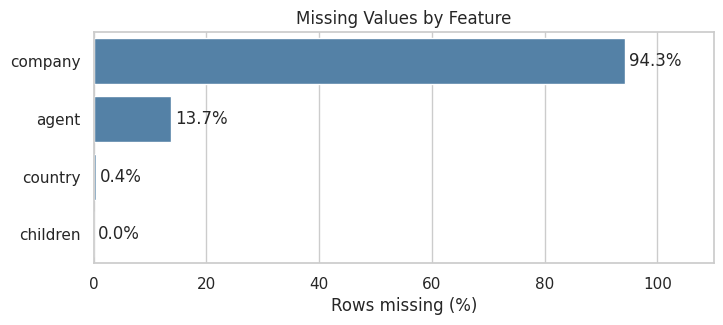

In [13]:
# Count and percent of missing values in each column.
missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": df.isna().mean() * 100,
})
# Keep only the columns which really have missing values.
missing_summary = missing_summary[missing_summary["missing_count"] > 0].sort_values(
    "missing_percent", ascending=False)
display(missing_summary.round(2))

# Bar chart of the missing percent.
plt.figure(figsize=(8, 3))
ax = sns.barplot(x=missing_summary["missing_percent"], y=missing_summary.index, color="steelblue")
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3)
plt.title("Missing Values by Feature")
plt.xlabel("Rows missing (%)")
plt.ylabel("")
plt.xlim(0, 110)
plt.show()

**What we found and what we did**

| Field | Missing | Treatment | Why |
|---|---|---|---|
| `company` | 112,593 (94.31%) | Filled with 0 ("no company recorded") | Missing most likely means no company was involved |
| `agent` | 16,340 (13.69%) | Filled with 0 ("no agent recorded") | Same reason |
| `country` | 488 (0.41%) | "Unknown" category | Too few rows to justify imputation |
| `children` | 4 (<0.01%) | Filled with 0 | Most bookings have no children (median 0) |

None of these fixes uses a statistic computed from the data, so nothing can leak from the test period into training. Later we treat `agent` and `company` as categories, so 0 simply means "none".

In [14]:
# Fill the missing values.
# children: 0, because most bookings have no children.
df["children"] = df["children"].fillna(0)
# country: Unknown. We do not guess a country.
df["country"] = df["country"].fillna("Unknown")
# agent and company: 0 means no agent or no company (same as the data paper says).
df["agent"] = df["agent"].fillna(0)      # 0 = no agent recorded
df["company"] = df["company"].fillna(0)  # 0 = no company recorded

# Safety check: no missing value should be left in these four columns.
cols = ["children", "country", "agent", "company"]
assert df[cols].isna().sum().sum() == 0
print("Missing values after handling:\n", df[cols].isna().sum())

Missing values after handling:
 children    0
country     0
agent       0
company     0
dtype: int64


### 4.2 Duplicate records

We count the exact duplicate rows and check how they change the cancellation rate, because duplicates can bias both the rate and any model score.

In [15]:
# Mark the rows which are exact copies of an earlier row.
duplicate_mask = df_raw.duplicated()
print(f"Exact duplicate rows: {duplicate_mask.sum():,} ({duplicate_mask.mean():.2%})")

# Compare the cancellation rate in three versions of the data:
# all rows, without duplicates, and duplicates only.
duplicate_sensitivity = pd.DataFrame({
    "version": ["All rows retained", "One row per exact pattern", "Duplicate rows only"],
    "rows": [len(df_raw), (~duplicate_mask).sum(), duplicate_mask.sum()],
    "cancellation_rate_percent": [
        df_raw["is_canceled"].mean() * 100,
        df_raw.loc[~duplicate_mask, "is_canceled"].mean() * 100,
        df_raw.loc[duplicate_mask, "is_canceled"].mean() * 100,
    ],
}).round(2)
display(duplicate_sensitivity)

Exact duplicate rows: 31,994 (26.80%)


,version,rows,cancellation_rate_percent
0,All rows retained,119390,37.04
1,One row per exact pattern,87396,27.49
2,Duplicate rows only,31994,63.13


**What we found.** 31,994 rows (26.80%) are exact duplicates. If we keep only one row per pattern, 87,396 rows are left and the cancellation rate drops from 37.04% to 27.49%. So the duplicated rows are cancelled much more often than the rest.

**Our decision: keep all rows.** There is no booking ID, so identical rows could easily be separate bookings that just look the same (agent or group bookings, for example). Deleting them might throw away real reservations. Duplicates also share an arrival date, so they cannot end up on both sides of the train/test boundary. In Part 2 we report results on the full data and on the one-row-per-pattern data.


In [16]:
# Take only the duplicate rows. Then see what kind of bookings they are.
dup = df_raw[duplicate_mask]
# Compare market segment share: duplicates against all rows.
composition = pd.DataFrame({
    "duplicates_%": dup["market_segment"].value_counts(normalize=True) * 100,
    "all_rows_%": df_raw["market_segment"].value_counts(normalize=True) * 100,
}).round(1)
display(composition)
# Share of duplicates in each hotel.
print(dup["hotel"].value_counts(normalize=True).round(3))

,duplicates_%,all_rows_%
market_segment,,
Aviation,0.0,0.2
Complementary,0.1,0.6
Corporate,3.4,4.4
Direct,2.5,10.6
Groups,46.5,16.6
Offline TA/TO,32.3,20.3
Online TA,15.2,47.3
Undefined,NaN,0.0


hotel
City Hotel      0.81
Resort Hotel    0.19
Name: proportion, dtype: float64


The duplicates are concentrated in particular booking types. Groups are 46.5% of the duplicate rows but only 16.6% of all rows. Offline TA/TO is 32.3% against 20.3%, and the City Hotel is 81% against 66%. Online TA is under-represented (15.2% against 47.3%).

This looks like repeated, identical group or agent reservations and not accidental copies, though without a booking ID we can't prove it.

### 4.3 Outliers and invalid values

We screen for extreme values with 1.5 × IQR fences and boxplots, and we count invalid values. We decide based on whether a value is plausible, not just on where the fence is.

,Feature,Min,Max,Lower Fence,Upper Fence,Outlier Count,Outlier %
0,lead_time,0.00,737.0,-195.00,373.00,3005,2.52
1,adr,-6.38,5400.0,-15.77,211.06,3793,3.18
2,adults,0.00,55.0,2.00,2.00,29710,24.88
3,stays_in_week_nights,0.00,50.0,-2.00,6.00,3354,2.81
4,stays_in_weekend_nights,0.00,19.0,-3.00,5.00,265,0.22
5,days_in_waiting_list,0.00,391.0,0.00,0.00,3698,3.10


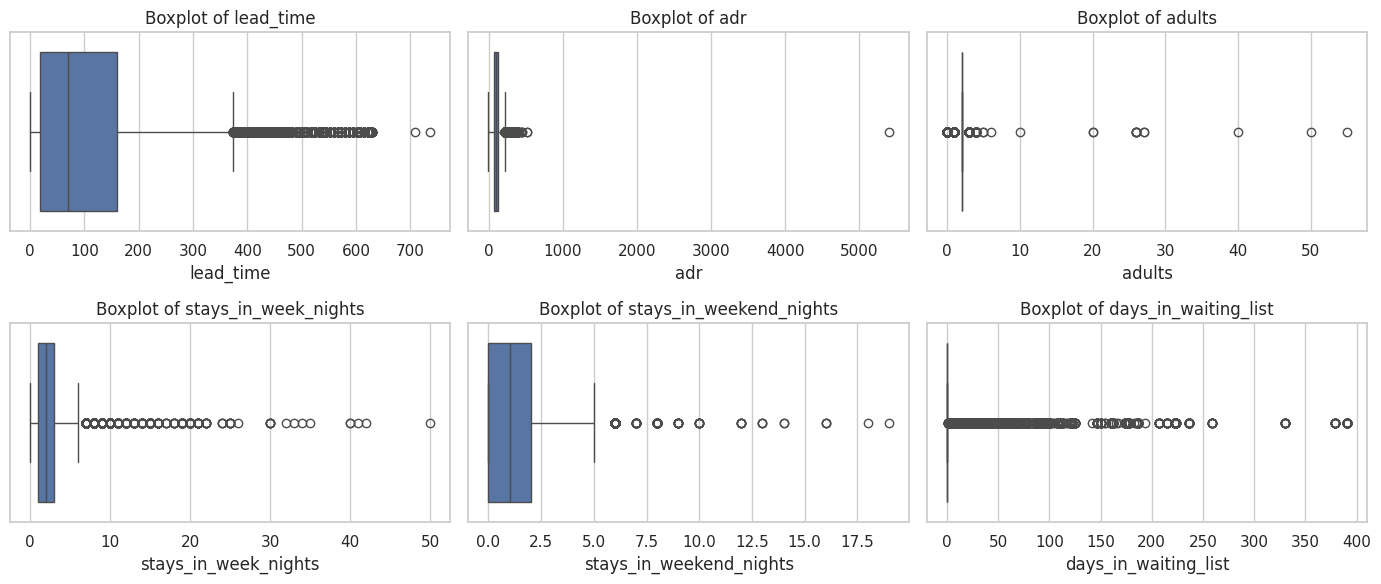

Negative ADR values: 1
ADR values above 1,000: 1
Bookings with zero guests: 180
Bookings with zero nights: 715


In [17]:
# Columns where we check for outliers.
outlier_columns = ["lead_time", "adr", "adults", "stays_in_week_nights",
                   "stays_in_weekend_nights", "days_in_waiting_list"]

# IQR rule: a value below Q1 - 1.5*IQR or above Q3 + 1.5*IQR is called an outlier.
rows = []
for col in outlier_columns:
    # Q1 and Q3 are the 25th and 75th percentiles.
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    # Count how many values are outside the fences.
    n = ((df[col] < lo) | (df[col] > hi)).sum()
    rows.append([col, df[col].min(), df[col].max(), lo, hi, n, n / len(df) * 100])

# Show the outlier table.
display(pd.DataFrame(rows, columns=["Feature", "Min", "Max", "Lower Fence", "Upper Fence",
                                    "Outlier Count", "Outlier %"]).round(2))

# Boxplots, so we can see the outliers.
fig, axes = plt.subplots(2, 3, figsize=(14, 6))
for ax, col in zip(axes.ravel(), outlier_columns):
    sns.boxplot(x=df[col], ax=ax)
    ax.set_title(f"Boxplot of {col}")
plt.tight_layout()
plt.show()

# Count the invalid values: negative price, very high price, zero guests, zero nights.
print("Negative ADR values:", (df["adr"] < 0).sum())
print("ADR values above 1,000:", (df["adr"] > 1000).sum())
print("Bookings with zero guests:", ((df["adults"] + df["children"] + df["babies"]) == 0).sum())
print("Bookings with zero nights:", ((df["stays_in_week_nights"] + df["stays_in_weekend_nights"]) == 0).sum())

**What we found and decided**
- **`lead_time`:** the maximum is 737 days, and 3,005 bookings (2.52%) are above the upper fence of 373 days. Booking far ahead is plausible, so we keep them all.
- **`adults`, `stays_in_week_nights`, `days_in_waiting_list`:** maxima of 55, 50 and 391. These are rare, but they fit group bookings or long stays, so they are not clear errors and we keep them.
- **A limit of the IQR rule:** `adults` and `days_in_waiting_list` have an interquartile range of 0, so their fences collapse (29,710 and 3,698 values end up "outside"). For these two, the maximum tells us more than the fence count.
- **`adr`:** there is one negative value (−6.38) and one clear error (5,400, while the next largest is 510). We replace the negative value with the 2015–2016 median. Everything above the 2015–2016 99.9th percentile (305) is capped, which also trims a few plausible high prices (counted above). The cap is learned from 2015–2016 only.
- **Zero guests (180) and zero nights (715):** we count them and keep them. Part 2 tests how sensitive the results are to them.

We remove no rows, so the target distribution does not change.

In [18]:
# train is True for 2015-2016 rows.
# We learn every limit from these rows only, so the test data stays clean.
train = df["split"] == "train_val"     # thresholds are learned on 2015-2016 only

# Impossible negative price -> median of valid training-period prices
df.loc[df["adr"] < 0, "adr"] = df.loc[train & (df["adr"] >= 0), "adr"].median()

# Extreme prices -> capped at the 99.9th percentile of the training period
adr_cap = df.loc[train, "adr"].quantile(0.999)
print("ADR max before capping:", df["adr"].max())
# Count how many rows will be capped in training and in test.
n_clip_train = int(((df["adr"] > adr_cap) & train).sum())
n_clip_test = int(((df["adr"] > adr_cap) & ~train).sum())
print(f"Rows above the cap: {n_clip_train} in 2015-2016, {n_clip_test} in 2017")
df["adr"] = df["adr"].clip(upper=adr_cap)
print("ADR cap (99.9th percentile, 2015-2016):", round(adr_cap, 2), "| max after capping:", round(df["adr"].max(), 2))

# Final checks: no negative ADR, no missing ADR, and no row removed.
assert df["adr"].min() >= 0 and df["adr"].isna().sum() == 0
assert len(df) == len(df_raw)      # no rows removed

ADR max before capping: 5400.0
Rows above the cap: 67 in 2015-2016, 165 in 2017
ADR cap (99.9th percentile, 2015-2016): 305.0 | max after capping: 305.0


### 4.4 Categorical consistency
The proposal lists inconsistent category values as a risk, so we check the labels for stray spaces, placeholder values and different labels that mean the same thing.

In [19]:
# Text columns we want to check.
cat_check = ["hotel","meal","country","market_segment","distribution_channel",
             "reserved_room_type","assigned_room_type","deposit_type","customer_type","reservation_status"]
# Check 1: no extra spaces. Then print the unique values.
for c in cat_check:
    s = df[c].astype(str)
    assert (s == s.str.strip()).all(), f"whitespace in {c}"
    if c != "country":
        print(c, sorted(s.unique()))
# Check 2: count the Undefined labels and the country code lengths.
print("Undefined counts:", {c: int((df[c] == "Undefined").sum()) for c in cat_check})
print("Country code lengths:", df["country"].str.len().value_counts().to_dict())

# 'SC' and 'Undefined' both mean "no meal package" in the dataset documentation
df["meal"] = df["meal"].replace({"Undefined": "SC"})
print("meal after merge:", sorted(df["meal"].unique()))

hotel ['City Hotel', 'Resort Hotel']
meal ['BB', 'FB', 'HB', 'SC', 'Undefined']
market_segment ['Aviation', 'Complementary', 'Corporate', 'Direct', 'Groups', 'Offline TA/TO', 'Online TA', 'Undefined']
distribution_channel ['Corporate', 'Direct', 'GDS', 'TA/TO', 'Undefined']
reserved_room_type ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'L', 'P']
assigned_room_type ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'K', 'L', 'P']
deposit_type ['No Deposit', 'Non Refund', 'Refundable']
customer_type ['Contract', 'Group', 'Transient', 'Transient-Party']
reservation_status ['Canceled', 'Check-Out', 'No-Show']
Undefined counts: {'hotel': 0, 'meal': 1169, 'country': 0, 'market_segment': 2, 'distribution_channel': 5, 'reserved_room_type': 0, 'assigned_room_type': 0, 'deposit_type': 0, 'customer_type': 0, 'reservation_status': 0}
Country code lengths: {3: 117623, 2: 1279, 7: 488}
meal after merge: ['BB', 'FB', 'HB', 'SC']


**What we found and decided.** There are no whitespace problems. `meal` has two labels for "no package", SC and Undefined (1,169 rows), so we merge them into SC. `market_segment` has 2 "Undefined" rows and `distribution_channel` has 5. We keep them as their own level, and the minimum-bookings filter hides them in the charts. `country` has codes of different lengths: 117,623 three-letter codes, 1,279 two-letter codes and 488 seven-character values ("Unknown", which comes from our missing-value fill).

## 5. Data Preprocessing

We only apply changes that need no statistic from the evaluation period. Arrival month becomes an ordered category, and count-like or ID columns stored as floats become integers. Imputation, encoding and scaling wait until Part 2, where they are fitted inside the training folds only.

In [20]:
# Make month an ordered category (January to December).
df["arrival_date_month"] = pd.Categorical(df["arrival_date_month"], categories=month_order, ordered=True)

# Count-like and identifier columns stored as floats become integers
for col in ["children", "agent", "company"]:
    df[col] = df[col].astype(int)

# Check the new data types.
display(df[["arrival_date_month", "children", "agent", "company", "is_canceled", "split"]].dtypes.to_frame("dtype"))
# Bookings and cancellation rate in each split and hotel.
display(df.groupby(["split", "hotel"]).agg(bookings=("is_canceled", "size"),
                                           cancellation_rate=("is_canceled", "mean")).round(3))

,dtype
arrival_date_month,category
children,int64
agent,int64
company,int64
is_canceled,int64
split,object


bookings  cancellation_rate
split     hotel                                    
test      City Hotel       27508              0.425
          Resort Hotel     13179              0.308
train_val City Hotel       51822              0.413
          Resort Hotel     26881              0.263

**Scope of this section.** This section only changes types and ordering. The full pipeline that imputes, log-transforms, scales and encodes is defined in Section 7.3. It is fitted on 2015–2016 only and then applied to 2017 without refitting.

## 6. Feature Engineering

We create new variables that describe booking behaviour more directly than the raw columns. Every threshold is learned from 2015–2016 only.

| Feature | Definition | Why we made it |
|---|---|---|
| `total_nights` | Week nights + weekend nights | Overall stay length |
| `total_guests` | Adults + children + babies | Party size |
| `is_family` | 1 if children or babies are present | Family travel behaviour |
| `weekend_stay` | 1 if at least one weekend night | Leisure versus business pattern |
| `is_domestic` | 1 if country is PRT | Portuguese guests are the largest market (see 8.9) |
| `high_adr` | 1 if ADR is above the 2015-2016 75th percentile | Price tier |
| `lead_time_group` | 0-7, 8-30, 31-90, 91-180, 181-365, >365 days | Captures the non-linear lead-time effect in readable groups |
| `has_agent`, `has_company` | 1 if an agent or company ID is recorded | Keeps the signal without high-cardinality IDs |
| `was_waitlisted`, `has_previous_cancel` | Waiting-list days > 0; previous cancellations > 0 | Handles sparse columns that are mostly zeros |
| `arrival_weekday` | Day of week of arrival | Weekday versus weekend arrival behaviour |
| `nights_group`, `booking_changes_group` | Binned total nights and booking changes | Readable groups for the EDA |

In [21]:

# Now we create new features. Each one is simple and easy to explain.
# total_nights = week nights + weekend nights.
df["total_nights"] = df["stays_in_week_nights"] + df["stays_in_weekend_nights"]
# total_guests = adults + children + babies.
df["total_guests"] = df["adults"] + df["children"] + df["babies"]
# is_family = 1 if there is any child or baby.
df["is_family"] = ((df["children"] > 0) | (df["babies"] > 0)).astype(int)
# weekend_stay = 1 if the guest stays at least one weekend night.
df["weekend_stay"] = (df["stays_in_weekend_nights"] > 0).astype(int)
# is_domestic = 1 if the guest is from Portugal (PRT).
df["is_domestic"] = (df["country"] == "PRT").astype(int)

# high_adr = 1 if the price is in the top 25%. The cut-off comes from 2015-2016 only.
adr_q75 = df.loc[train, "adr"].quantile(0.75)    # threshold from 2015-2016 only
df["high_adr"] = (df["adr"] > adr_q75).astype(int)

# Put lead time into groups (0-7 days, 8-30 days and so on). Easy to read in charts.
df["lead_time_group"] = pd.cut(
    df["lead_time"],
    bins=[-1, 7, 30, 90, 180, 365, np.inf],
    labels=["0-7 days", "8-30 days", "31-90 days", "91-180 days", "181-365 days", ">365 days"],
)


# Agent and company are ID numbers. We keep only yes/no flags.
df["has_agent"] = (df["agent"] > 0).astype(int)                  # agent was filled with 0 = no agent
df["has_company"] = (df["company"] > 0).astype(int)              # company was filled with 0 = no company
# Flags for waiting list and previous cancellation. These columns are mostly zeros.
df["was_waitlisted"] = (df["days_in_waiting_list"] > 0).astype(int)
df["has_previous_cancel"] = (df["previous_cancellations"] > 0).astype(int)

# Day name of arrival (Monday, Tuesday and so on).
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
df["arrival_weekday"] = pd.Categorical(df["arrival_date"].dt.day_name(),
                                       categories=weekday_order, ordered=True)

# Groups for number of nights and booking changes. We use these in the EDA.
df["nights_group"] = pd.cut(df["total_nights"], [-1, 0, 1, 3, 7, 14, np.inf],
                            labels=["0", "1", "2-3", "4-7", "8-14", "15+"])
df["booking_changes_group"] = pd.cut(df["booking_changes"], [-1, 0, 1, 2, np.inf],
                                     labels=["0", "1", "2", "3+"])

# Checks: we rebuild each feature in a simple way and compare.
# --- Validation of the engineered features ---
assert (df["total_nights"] == df["stays_in_week_nights"] + df["stays_in_weekend_nights"]).all()
assert (df["total_guests"] == df["adults"] + df["children"] + df["babies"]).all()
assert (df["is_family"] == ((df["children"] > 0) | (df["babies"] > 0)).astype(int)).all()
assert (df["weekend_stay"] == (df["stays_in_weekend_nights"] > 0).astype(int)).all()
assert df["lead_time_group"].notna().all()
assert (df["has_agent"] == (df["agent"] > 0).astype(int)).all()
assert (df["has_company"] == (df["company"] > 0).astype(int)).all()
assert df[["arrival_weekday", "nights_group", "booking_changes_group"]].notna().all().all()
print("All feature checks passed. ADR 75th percentile (2015-2016):", adr_q75)

# Summary of the new count and yes/no features.
display(df[["total_nights", "total_guests", "is_family", "weekend_stay", "is_domestic",
            "high_adr", "has_agent", "has_company", "was_waitlisted", "has_previous_cancel"]]
        .describe().T.round(3))

All feature checks passed. ADR 75th percentile (2015-2016): 117.3


,count,mean,std,min,25%,50%,75%,max
total_nights,119390.0,3.428,2.557,0.0,2.0,3.0,4.0,69.0
total_guests,119390.0,1.968,0.722,0.0,2.0,2.0,2.0,55.0
is_family,119390.0,0.078,0.268,0.0,0.0,0.0,0.0,1.0
weekend_stay,119390.0,0.564,0.496,0.0,0.0,1.0,1.0,1.0
is_domestic,119390.0,0.407,0.491,0.0,0.0,0.0,1.0,1.0
high_adr,119390.0,0.304,0.460,0.0,0.0,0.0,1.0,1.0
has_agent,119390.0,0.863,0.344,0.0,1.0,1.0,1.0,1.0
has_company,119390.0,0.057,0.232,0.0,0.0,0.0,0.0,1.0
was_waitlisted,119390.0,0.031,0.173,0.0,0.0,0.0,0.0,1.0
has_previous_cancel,119390.0,0.054,0.227,0.0,0.0,0.0,0.0,1.0


**What we noticed.** The average stay is 3.43 nights (maximum 69). 86.3% of bookings come through an agent, but only 5.7% involve a company. 3.1% were waitlisted and 5.4% have a previous cancellation. 7.8% are family bookings, 56.4% include a weekend night and 40.7% are Portuguese. The share above the historical ADR threshold went up, which may come from price changes or from a change in the booking mix.

## 7. Feature Selection: Leakage Audit

### 7.1 Timing audit
The prediction is made the moment a reservation is created, so a column is only usable if its value is already known at that moment. We put every column into one of three groups: candidate, ambiguous (could be recorded or updated after booking) or excluded (gives away or follows the outcome). We choose by this timing rule and not by model performance, so the test period can't influence the choice.

In [22]:
# Table: when is each column known?
# Only columns known at booking time can be used for prediction.
feature_timing_audit = pd.DataFrame(
    [
        ["hotel, lead_time, arrival date fields, stay length, guests, market_segment, customer_type, previous bookings", "Known at reservation", "Candidate predictors"],
        ["reserved_room_type, meal, country, distribution_channel, agent, company", "Known at reservation", "Candidate predictors"],
        ["adr", "Lodging revenue per night; can be updated during the stay", "Candidate; test with and without"],
        ["deposit_type", "Known at booking; Non Refund pattern needs a definition check", "Candidate; test with and without"],
        ["booking_changes", "Accumulates until check-in or cancellation", "Ambiguous"],
        ["days_in_waiting_list", "Accumulates after the booking is entered", "Ambiguous"],
        ["required_car_parking_spaces", "No cancelled booking requires parking; likely recorded at or after arrival", "Ambiguous"],
        ["total_of_special_requests", "Can be added after the booking is made", "Ambiguous"],
        ["assigned_room_type", "Can change up to check-in", "Excluded"],
        ["reservation_status", "Final status; reveals the outcome", "Excluded"],
        ["reservation_status_date", "Recorded after the outcome", "Excluded"],
        ["is_canceled", "Final outcome", "Target"],
        ["arrival_date_year", "Defines the chronological split", "Not a predictor"],
    ],
    columns=["feature", "timing", "decision"],
)
# Show the audit table.
display(feature_timing_audit)

# Does reservation_status reproduce the target?
display(pd.crosstab(df_raw["reservation_status"], df_raw["is_canceled"]))

,feature,timing,decision
0,"hotel, lead_time, arrival date fields, stay length, guests, market_segment, customer_type, previous bookings",Known at reservation,Candidate predictors
1,"reserved_room_type, meal, country, distribution_channel, agent, company",Known at reservation,Candidate predictors
2,adr,Lodging revenue per night; can be updated during the stay,Candidate; test with and without
3,deposit_type,Known at booking; Non Refund pattern needs a definition check,Candidate; test with and without
4,booking_changes,Accumulates until check-in or cancellation,Ambiguous
5,days_in_waiting_list,Accumulates after the booking is entered,Ambiguous
6,required_car_parking_spaces,No cancelled booking requires parking; likely recorded at or after arrival,Ambiguous
7,total_of_special_requests,Can be added after the booking is made,Ambiguous
8,assigned_room_type,Can change up to check-in,Excluded
9,reservation_status,Final status; reveals the outcome,Excluded


is_canceled,0,1
reservation_status,,
Canceled,0,43017
Check-Out,75166,0
No-Show,0,1207


**What we found.** Every value of `reservation_status` maps to exactly one value of `is_canceled` (see the crosstab above), so using it would simply hand the model the answer. We exclude it, together with `reservation_status_date` and `assigned_room_type`. Of the 44,224 rows with `is_canceled` = 1, 43,017 are "Canceled" and 1,207 are "No-Show", so the target counts no-shows as cancellations. Four columns (`booking_changes`, `days_in_waiting_list`, `required_car_parking_spaces`, `total_of_special_requests`) may be recorded after the booking, and `adr` builds up from lodging transactions. We keep these for analysis and test them separately in Part 2. The original columns stay in `df_raw`, so Part 2 can measure the effect of leakage (research question 1) with a deliberately leaky feature set.

In [23]:
# Columns that give away the answer. We remove them from df.
leakage_features = ["reservation_status", "reservation_status_date", "assigned_room_type"]
# Columns that may be filled after booking. We keep them only for testing.
ambiguous_features = ["booking_changes", "days_in_waiting_list",
                      "required_car_parking_spaces", "total_of_special_requests"]

df = df.drop(columns=leakage_features, errors="ignore")   # df_raw still holds them for the Phase 2 leakage comparison
# Check that the leaky columns are really gone.
assert not set(leakage_features) & set(df.columns)
print("Leakage columns removed. New shape:", df.shape)
print("Ambiguous (kept for EDA, tested separately in Phase 2):", ambiguous_features)

Leakage columns removed. New shape: (119390, 45)
Ambiguous (kept for EDA, tested separately in Phase 2): ['booking_changes', 'days_in_waiting_list', 'required_car_parking_spaces', 'total_of_special_requests']


### 7.2 Feature selection and the three feature sets
Selection follows the timing rule from the audit, plus a check for redundancy. We build three sets so that Part 2 can measure how much of the apparent performance comes from columns that are not really known at reservation time (research question 1). Part 2 then adds three small variations of the main set for extra checks.

| Dropped from all sets | Why |
|---|---|
| `arrival_date_week_number`, `arrival_date_day_of_month` | Redundant with arrival month and weekday, and the day of month has no expected signal |
| `stays_in_week_nights`, `stays_in_weekend_nights` | They are exact components of `total_nights`, and `weekend_stay` keeps the weekend information |
| `adults`, `children`, `babies` | Captured by `total_guests` and `is_family` |
| `is_domestic`, `high_adr`, `lead_time_group` | Redundant with the country one-hot, `adr` and `lead_time` (kept for EDA only) |
| `agent`, `company` | IDs, replaced by `has_agent` and `has_company` |
| `arrival_date_year`, `arrival_date`, `split` | They define the split and are not predictors |

In [24]:
# Feature groups.
# NUM = number columns, BIN = yes/no columns, CAT = category columns.
NUM_STRICT = ["lead_time", "adr", "total_nights", "total_guests",
              "previous_cancellations", "previous_bookings_not_canceled"]
BIN_STRICT = ["is_repeated_guest", "is_family", "weekend_stay", "has_agent", "has_company"]
CAT_STRICT = ["hotel", "arrival_date_month", "arrival_weekday", "meal", "country",
              "market_segment", "distribution_channel", "reserved_room_type", "customer_type"]
# Four columns which may be updated after booking.
AMBIGUOUS = ["booking_changes", "days_in_waiting_list",
             "required_car_parking_spaces", "total_of_special_requests"]
LEAKY_CAT = ["assigned_room_type", "reservation_status"]     # still held in df_raw
DEPOSIT_OPTION = ["deposit_type"]                            # added in Phase 2 to test with and without

# Three feature sets.
# A = only safe columns. B = A + ambiguous columns.
# C = B + leaky columns (only for comparison).
feature_sets = {
    "A_strict":                {"num": NUM_STRICT, "bin": BIN_STRICT, "cat": CAT_STRICT},
    "B_strict_plus_ambiguous": {"num": NUM_STRICT + AMBIGUOUS, "bin": BIN_STRICT, "cat": CAT_STRICT},
    "C_leaky_benchmark":       {"num": NUM_STRICT + AMBIGUOUS, "bin": BIN_STRICT, "cat": CAT_STRICT + LEAKY_CAT},
}

# Join the leaky columns back from df_raw, because set C needs them.
model_frame = df.join(df_raw[LEAKY_CAT])                     # same index as df_raw
# Check that every column name really exists.
for name, s in feature_sets.items():
    missing = [c for g in s.values() for c in g if c not in model_frame.columns]
    assert not missing, (name, missing)

# Split by time again. Train = 2015-2016. Test = 2017.
train_df = model_frame[model_frame["split"] == "train_val"]
test_df = model_frame[model_frame["split"] == "test"]

# Show the size and purpose of each feature set.
display(pd.DataFrame({
    "feature_set": list(feature_sets),
    "n_columns": [sum(len(g) for g in s.values()) for s in feature_sets.values()],
    "purpose": ["Honest reservation-time model (headline result)",
                "Tests whether post-booking fields inflate performance",
                "Deliberately leaky benchmark to quantify the leakage effect (RQ1)"],
}))

,feature_set,n_columns,purpose
0,A_strict,20,Honest reservation-time model (headline result)
1,B_strict_plus_ambiguous,24,Tests whether post-booking fields inflate performance
2,C_leaky_benchmark,26,Deliberately leaky benchmark to quantify the leakage effect (RQ1)


### 7.3 Leakage-safe preprocessing pipeline
We define imputation, log transformation, scaling and encoding as one pipeline. It is fitted on 2015–2016 only and applied to 2017 with `transform`, so no test statistic is used. The 2017 transform here is only a check that the pipeline runs. We don't evaluate anything in Part 1.

In [25]:
# Tools from scikit-learn to build the preprocessing pipeline.
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.impute import SimpleImputer

# This function builds the preprocessing steps.
# It is fitted on training data only, so there is no leakage.
def make_preprocessor(num_cols, bin_cols, cat_cols):
    # Skewed columns get a log transform. The other number columns are only scaled.
    log_cols = [c for c in ("lead_time", "adr", "days_in_waiting_list") if c in num_cols]   # right-skewed
    plain = [c for c in num_cols if c not in log_cols]
    # Different steps for different column types:
    # 1) log columns: fill missing, log, scale
    # 2) other number columns: fill missing, scale
    # 3) yes/no columns: no change
    # 4) category columns: one-hot encoding (rare values are grouped together)
    return ColumnTransformer([
        ("log_scale", Pipeline([("imp", SimpleImputer(strategy="median")),
                                ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
                                ("sc", StandardScaler())]), log_cols),
        ("scale", Pipeline([("imp", SimpleImputer(strategy="median")),
                            ("sc", StandardScaler())]), plain),
        ("bin", "passthrough", bin_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=100, sparse_output=False), cat_cols),
    ])

# Test the pipeline on all three feature sets.
# This is only a run check. We do not train any model in Part 1.
for name, s in feature_sets.items():
    cols = s["num"] + s["bin"] + s["cat"]
    pre = make_preprocessor(s["num"], s["bin"], s["cat"])
    Xtr = pre.fit_transform(train_df[cols])     # fitted on 2015-2016 only
    Xte = pre.transform(test_df[cols])          # transform only
    assert not np.isnan(Xtr).any() and not np.isnan(Xte).any()
    print(f"{name}: train {Xtr.shape}, test {Xte.shape}")

A_strict: train (78703, 96), test (40687, 96)
B_strict_plus_ambiguous: train (78703, 100), test (40687, 100)
C_leaky_benchmark: train (78703, 114), test (40687, 114)


**Result.** The pipeline runs on all three sets: 96 features for A (strict), 100 for B (adds four ambiguous columns) and 114 for C (adds the leaky columns). There are no missing values after transformation, and train and test have identical columns.

## 8. Exploratory Data Analysis

We report every rate together with the number of bookings (n). Group tables and bar charts carry 95% Wilson intervals. The monthly line chart and the heatmaps show rates without intervals, but each heatmap cell shows n and is hidden when n is below 50. These intervals treat bookings as independent, which is a bit optimistic because duplicate rows and group bookings are correlated. The descriptive plots use all arrivals, including 2017, so we can see drift. The association and feature-selection analysis (8.12) uses 2015–2016 only, so 2017 stays untouched for model development.

### 8.1 Cancellation distribution

,bookings,percent
is_canceled,,
0,75166,62.96
1,44224,37.04


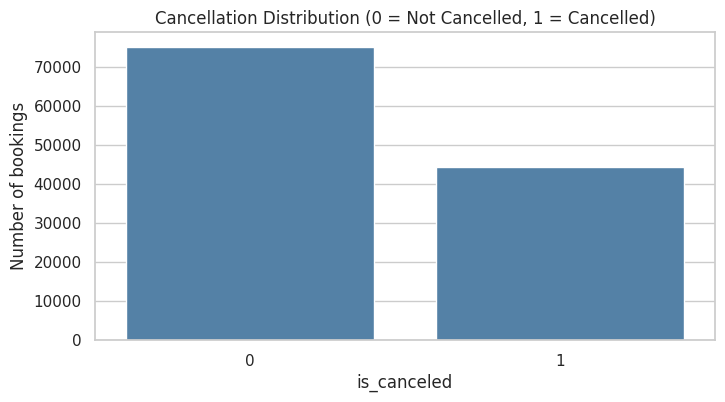

In [26]:
# Count and percent of cancelled and not cancelled bookings.
target_summary = df["is_canceled"].value_counts().sort_index().to_frame("bookings")
target_summary["percent"] = target_summary["bookings"] / len(df) * 100
display(target_summary.round(2))

# Bar chart of the target column.
sns.countplot(x="is_canceled", data=df, color="steelblue")
plt.title("Cancellation Distribution (0 = Not Cancelled, 1 = Cancelled)")
plt.ylabel("Number of bookings")
plt.show()

**What we found.** 44,224 of 119,390 bookings (37.04%) are cancelled, including 1,207 no-shows, and 75,166 (62.96%) are not. The imbalance is moderate.

Accuracy is a poor metric here, because a model that always says "not cancelled" would already score 62.96%. That is why Average Precision (PR-AUC) is the main metric in Part 2, as in the proposal.

### 8.2 Cancellation by hotel

,hotel,bookings,cancellations,cancellation_rate,ci_low,ci_high
0,City Hotel,79330,33102,0.417,0.414,0.421
1,Resort Hotel,40060,11122,0.278,0.273,0.282


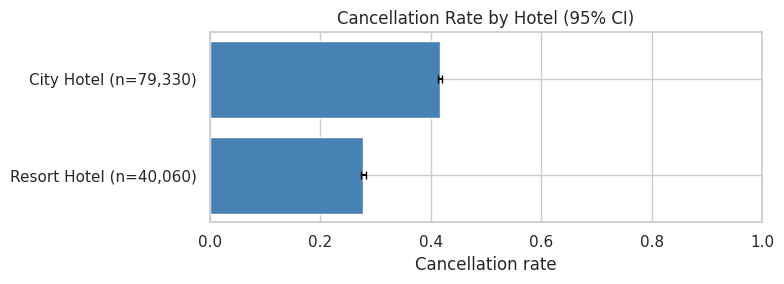

In [27]:
# Cancellation rate for each hotel, with 95% CI (using our helper functions).
hotel_rates = cancellation_summary(df, "hotel")
display(hotel_rates.round(3))
plot_rates(hotel_rates, "hotel", "Cancellation Rate by Hotel (95% CI)")

**What we found.** The City Hotel cancels 41.7% of its bookings (33,102 of 79,330; 95% CI 41.4–42.1%) and the Resort Hotel 27.8% (11,122 of 40,060; 27.3–28.2%). The intervals don't overlap, and the gap is about 14 percentage points. Hotel type is informative, but the two properties may behave differently, so we will test whether a model transfers between them (research question 4) and not just assume it.

### 8.3 Cancellation by lead time

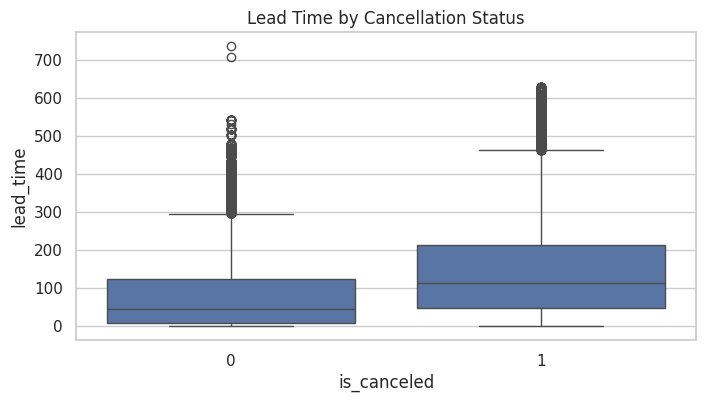

,lead_time_group,bookings,cancellations,cancellation_rate,ci_low,ci_high
0,0-7 days,19746,1902,0.096,0.092,0.101
1,8-30 days,18960,5283,0.279,0.272,0.285
2,31-90 days,29553,11141,0.377,0.371,0.383
3,91-180 days,26439,11821,0.447,0.441,0.453
4,181-365 days,21544,11947,0.555,0.548,0.561
5,>365 days,3148,2130,0.677,0.660,0.693


,hotel,lead_time_group,bookings,cancellations,cancellation_rate,ci_low,ci_high
0,City Hotel,0-7 days,10808,1319,0.122,0.116,0.128
1,City Hotel,8-30 days,12554,3880,0.309,0.301,0.317
2,City Hotel,31-90 days,20797,8300,0.399,0.392,0.406
3,City Hotel,91-180 days,18223,8746,0.480,0.473,0.487
4,City Hotel,181-365 days,14244,8934,0.627,0.619,0.635
5,City Hotel,>365 days,2704,1923,0.711,0.694,0.728
6,Resort Hotel,0-7 days,8938,583,0.065,0.060,0.071
7,Resort Hotel,8-30 days,6406,1403,0.219,0.209,0.229
8,Resort Hotel,31-90 days,8756,2841,0.324,0.315,0.334
9,Resort Hotel,91-180 days,8216,3075,0.374,0.364,0.385


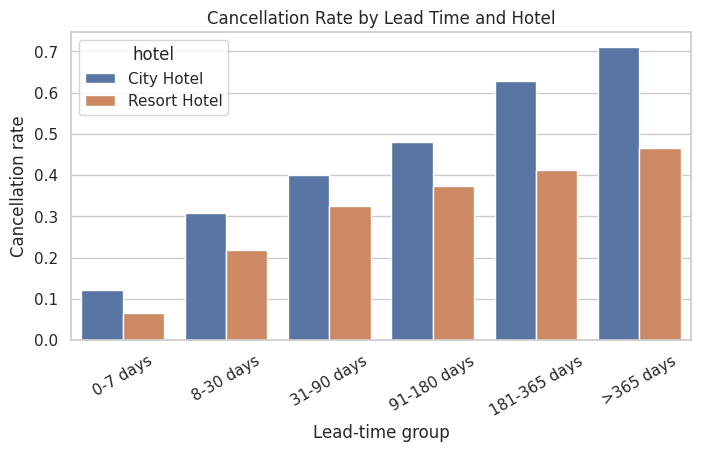

In [28]:
# Lead time for cancelled and not cancelled bookings.
sns.boxplot(x="is_canceled", y="lead_time", data=df)
plt.title("Lead Time by Cancellation Status")
plt.show()

# Cancellation rate in each lead time group.
display(cancellation_summary(df, "lead_time_group", sort=False).round(3))

# Same thing, but separately for each hotel.
lead_by_hotel = cancellation_summary(df, ["hotel", "lead_time_group"], sort=False)
display(lead_by_hotel.round(3))
# Bar chart: lead time group against cancellation rate. One colour for each hotel.
sns.barplot(data=lead_by_hotel, x="lead_time_group", y="cancellation_rate", hue="hotel")
plt.xticks(rotation=30)
plt.ylabel("Cancellation rate")
plt.xlabel("Lead-time group")
plt.title("Cancellation Rate by Lead Time and Hotel")
plt.show()

**What we found.** For both hotels together, the cancellation rate goes up steadily with lead time: 9.6% (0–7 days), 27.9% (8–30), 37.7% (31–90), 44.7% (91–180), 55.5% (181–365) and 67.7% (more than 365 days). The same order holds inside each hotel. The longest group is small (2,704 bookings in the City Hotel and 444 in the Resort Hotel), so its rates are less precise. Lead time is known at reservation time, so it is a strong candidate predictor.

### 8.4 Cancellation over time

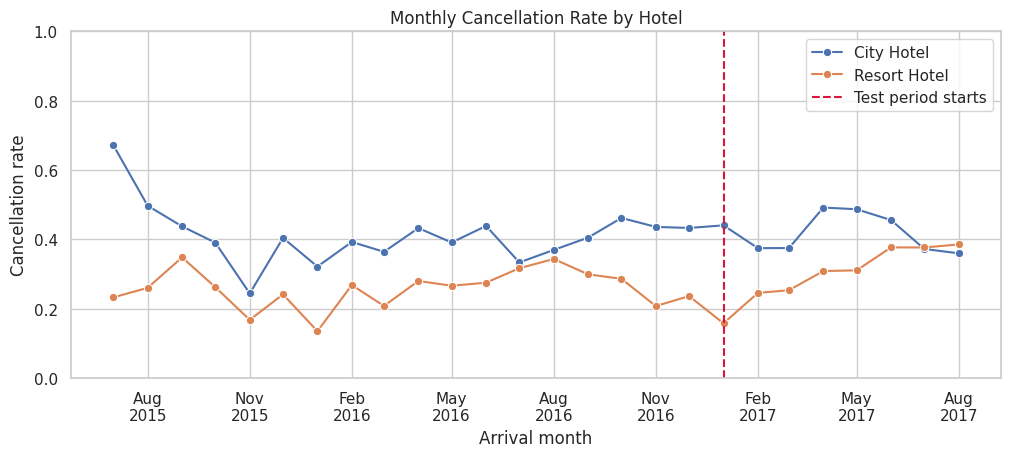

In [29]:
# Cancellation rate for each hotel in each month.
monthly = (df.assign(arrival_year_month=df["arrival_date"].dt.to_period("M").dt.to_timestamp())
             .groupby(["hotel", "arrival_year_month"])["is_canceled"]
             .agg(bookings="size", cancellation_rate="mean")
             .reset_index())

# Line chart over time. The red dotted line shows where the test period starts.
plt.figure(figsize=(12, 4.5))
sns.lineplot(data=monthly, x="arrival_year_month", y="cancellation_rate", hue="hotel", marker="o")
plt.axvline(pd.Timestamp("2017-01-01"), color="crimson", linestyle="--", label="Test period starts")
plt.gca().xaxis.set_major_locator(mdates.MonthLocator(interval=3))
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
plt.ylim(0, 1)
plt.xlabel("Arrival month")
plt.ylabel("Cancellation rate")
plt.title("Monthly Cancellation Rate by Hotel")
plt.legend()
plt.show()

**What we found.** Cancellation rates change over time, and the two hotels don't move together. The City Hotel starts very high in July 2015 (about 0.67), falls to about 0.25 by November 2015, and then moves roughly between 0.3 and 0.5 with no lasting trend. The Resort Hotel is lowest in winter and highest in summer every year, so part of its rise during 2017 is seasonal. Section 8.11 compares the same months of 2016 and 2017 to separate seasonality from real drift. Whether this drift makes a random split look better than it should is research question 2, and we test it in Part 2.

### 8.5 Cancellation by market segment

,market_segment,bookings,cancellations,cancellation_rate,ci_low,ci_high
0,Groups,19811,12097,0.611,0.604,0.617
1,Online TA,56477,20739,0.367,0.363,0.371
2,Offline TA/TO,24219,8311,0.343,0.337,0.349
3,Aviation,237,52,0.219,0.171,0.276
4,Corporate,5295,992,0.187,0.177,0.198
5,Direct,12606,1934,0.153,0.147,0.160
6,Complementary,743,97,0.131,0.108,0.157


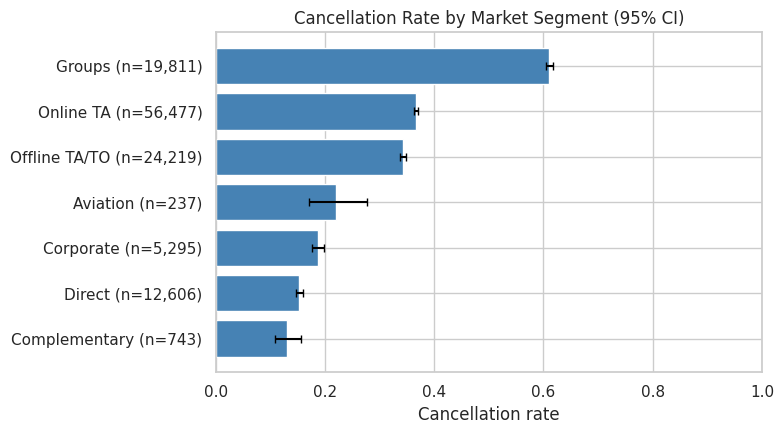

In [30]:
# Cancellation rate by market segment. We hide very small segments (less than 30 bookings).
segment_rates = cancellation_summary(df, "market_segment", min_bookings=30)
display(segment_rates.round(3))
plot_rates(segment_rates, "market_segment", "Cancellation Rate by Market Segment (95% CI)")

**What we found.** Groups cancel at 61.1% (n=19,811; 16.6% of all bookings), far above the 37.0% overall rate. Online TA (36.7%, n=56,477) and Offline TA/TO (34.3%, n=24,219) are close to average. The other segments are lower: Aviation 21.9% (n=237), Corporate 18.7% (n=5,295), Direct 15.3% (n=12,606) and Complementary 13.1% (n=743). Online TA has the most cancellations in total (20,739), but Groups is the only segment with a clearly higher rate. "Undefined" (2 bookings) is left out of the chart.

### 8.6 Lead time and market segment by hotel

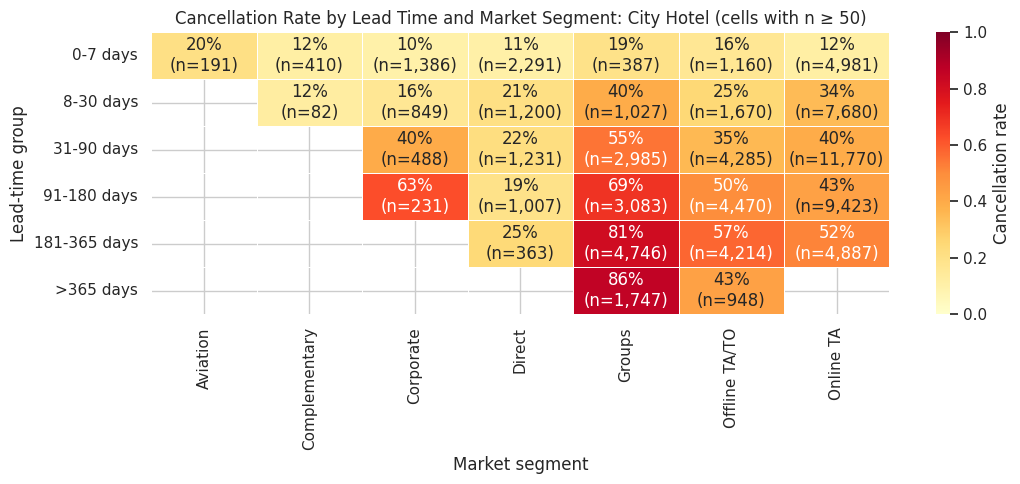

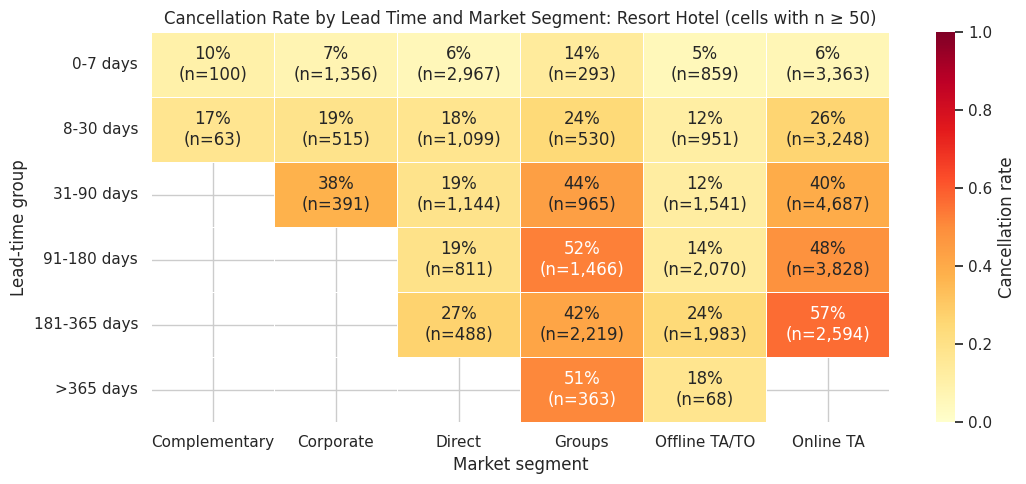

In [31]:
# One heatmap for each hotel: lead time group against market segment.
for hotel in ["City Hotel", "Resort Hotel"]:
    data = df[df["hotel"] == hotel]
    # rate = average cancellation in each cell.
    rate = data.pivot_table(index="lead_time_group", columns="market_segment",
                            values="is_canceled", aggfunc="mean", observed=False)
    # count = number of bookings in each cell.
    count = data.pivot_table(index="lead_time_group", columns="market_segment",
                             values="is_canceled", aggfunc="size", observed=False).fillna(0)

    keep = (count >= 50).any()                 # drop segments with no cell of at least 50 bookings
    rate, count = rate.loc[:, keep], count.loc[:, keep]
    # Text inside each cell: rate and n. We hide cells with less than 50 bookings.
    annotation = rate.apply(lambda col: [f"{r:.0%}\n(n={int(n):,})" if n >= 50 else ""
                                         for r, n in zip(col, count[col.name])])

    plt.figure(figsize=(11, 5))
    # Draw the heatmap. Small cells are masked.
    sns.heatmap(rate, mask=(count < 50), annot=annotation, fmt="", cmap="YlOrRd",
                vmin=0, vmax=1, linewidths=0.5, cbar_kws={"label": "Cancellation rate"})
    plt.title(f"Cancellation Rate by Lead Time and Market Segment: {hotel} (cells with n ≥ 50)")
    plt.xlabel("Market segment")
    plt.ylabel("Lead-time group")
    plt.tight_layout()
    plt.show()

**What we found.** The effect of lead time depends on the segment. In the City Hotel, Group bookings go from 19% (0–7 days, n=387) to 40% (8–30 days, n=1,027), 55% (31–90 days, n=2,985), 69% (91–180 days, n=3,083), 81% (181–365 days, n=4,746) and 86% (more than 365 days, n=1,747). Direct bookings stay between 11% and 25% in every lead-time group. The Resort Hotel shows the same direction at lower levels (for example Groups at 181–365 days: 42%, n=2,219). So lead time and segment should be modelled together and not as separate effects.

### 8.7 Two columns that need a closer look: deposit type and parking

,deposit_type,bookings,cancellations,cancellation_rate,ci_low,ci_high
0,Non Refund,14587,14494,0.994,0.992,0.995
1,No Deposit,104641,29694,0.284,0.281,0.287
2,Refundable,162,36,0.222,0.165,0.292


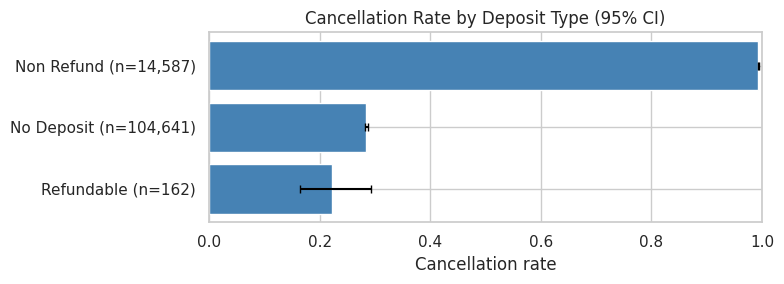

,required_car_parking_spaces,bookings,cancellations,cancellation_rate,ci_low,ci_high
0,0,111974,44224,0.395,0.392,0.398
1,1,7383,0,0.000,0.000,0.001
2,2,28,0,0.000,0.000,0.121
3,3,3,0,0.000,0.000,0.562
4,8,2,0,0.000,0.000,0.658


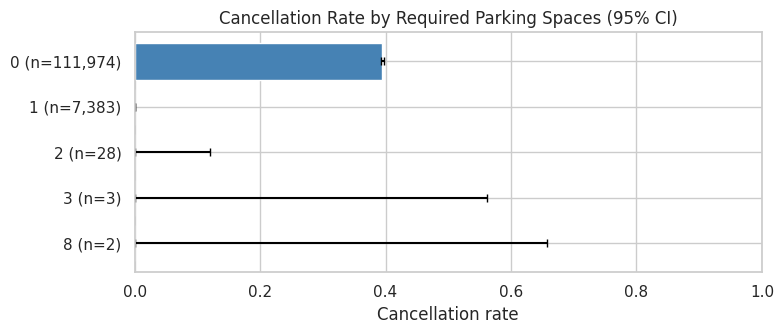

In [32]:
# Cancellation by deposit type.
deposit_rates = cancellation_summary(df, "deposit_type")
display(deposit_rates.round(3))
plot_rates(deposit_rates, "deposit_type", "Cancellation Rate by Deposit Type (95% CI)")

# Cancellation by parking spaces. Note: cancelled bookings never need parking (0 cancellations).
parking_rates = cancellation_summary(df, "required_car_parking_spaces", sort=False)
display(parking_rates.round(3))
plot_rates(parking_rates, "required_car_parking_spaces", "Cancellation Rate by Required Parking Spaces (95% CI)")

### 8.7b Where do Non Refund bookings sit?
A cancellation rate close to 100% under a refund-penalty policy is hard to believe. So we check whether it is concentrated in particular segments, hotels or countries.

In [33]:
# Look only at Non Refund bookings. Their cancellation rate is almost 100%, which is strange.
nr = df[df["deposit_type"] == "Non Refund"]

# Check by market segment.
display(pd.DataFrame({
    "non_refund_bookings": nr["market_segment"].value_counts(),
    "share_of_non_refund_%": nr["market_segment"].value_counts(normalize=True) * 100,
    "cancel_rate": nr.groupby("market_segment")["is_canceled"].mean(),
}).round(3))

# Check by hotel.
display(nr.groupby("hotel")["is_canceled"].agg(bookings="size", cancel_rate="mean").round(3))
# Check by year.
display(nr.groupby("arrival_date_year")["is_canceled"].agg(bookings="size", cancel_rate="mean").round(3))
# Share of Portuguese guests inside Non Refund bookings.
print("Share of Non Refund bookings from Portugal:", round((nr["country"] == "PRT").mean(), 3))

,non_refund_bookings,share_of_non_refund_%,cancel_rate
market_segment,,,
Corporate,334,2.290,0.934
Direct,19,0.130,0.842
Groups,9172,62.878,0.993
Offline TA/TO,5006,34.318,0.999
Online TA,56,0.384,0.946


,bookings,cancel_rate
hotel,,
City Hotel,12868,0.998
Resort Hotel,1719,0.960


,bookings,cancel_rate
arrival_date_year,,
2015,3667,0.998
2016,6794,0.989
2017,4126,0.998


Share of Non Refund bookings from Portugal: 0.972


**What we found.** Non Refund bookings cancel at almost 100% in every group, so the pattern is systematic and not tied to one segment. Groups make up 62.9% of them (9,172; 99.3% cancelled) and Offline TA/TO 34.3% (5,006; 99.9%). 88.2% are in the City Hotel (12,868; 99.8% cancelled; Resort 96.0%). The rate is stable across years (99.8%, 98.9% and 99.8% for 2015–2017), and 97.2% are Portuguese bookings. This looks like a recording or policy artefact linked to Portuguese group and agent bookings and not like real guest behaviour. The data can't confirm that, so Part 2 tests models with and without `deposit_type`.

### 8.8 Special requests and guest history

,total_of_special_requests,bookings,cancellations,cancellation_rate,ci_low,ci_high
0,0,70318,33556,0.477,0.474,0.481
1,1,33226,7318,0.220,0.216,0.225
2,2,12969,2866,0.221,0.214,0.228
3,3,2497,446,0.179,0.164,0.194
4,4,340,36,0.106,0.077,0.143
5,5,40,2,0.050,0.014,0.165


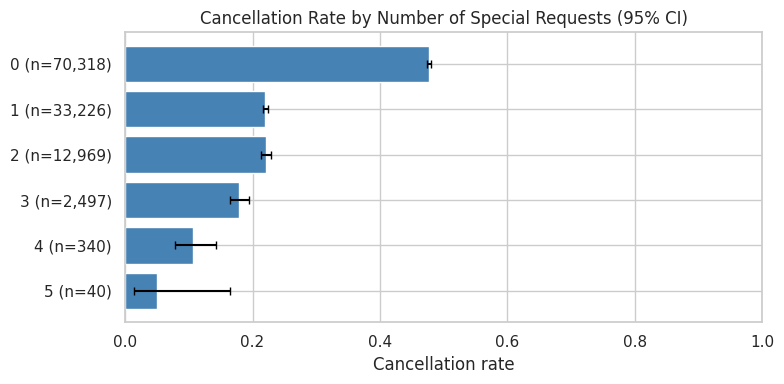

,is_repeated_guest,bookings,cancellations,cancellation_rate,ci_low,ci_high
0,New guest,115580,43672,0.378,0.375,0.381
1,Repeat guest,3810,552,0.145,0.134,0.156


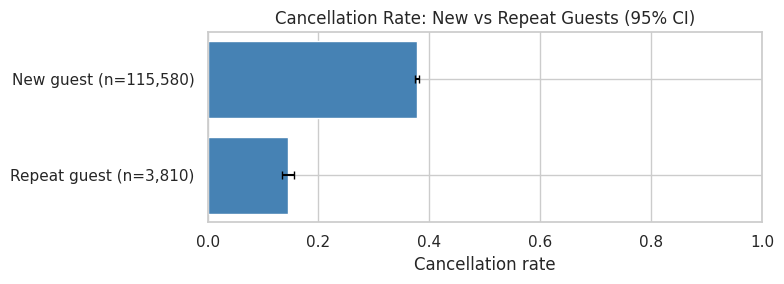

In [34]:
# Cancellation by number of special requests.
request_rates = cancellation_summary(df, "total_of_special_requests", sort=False)
display(request_rates.round(3))
plot_rates(request_rates, "total_of_special_requests", "Cancellation Rate by Number of Special Requests (95% CI)")

# Cancellation for new guests against repeat guests.
repeat_rates = cancellation_summary(df, "is_repeated_guest", sort=False)
# Change 0/1 into readable labels.
repeat_rates["is_repeated_guest"] = repeat_rates["is_repeated_guest"].map({0: "New guest", 1: "Repeat guest"})
display(repeat_rates.round(3))
plot_rates(repeat_rates, "is_repeated_guest", "Cancellation Rate: New vs Repeat Guests (95% CI)")

**What we found**
- **Special requests:** bookings with no request cancel at 47.7% (n=70,318). The rate drops to 22.0% with one request (n=33,226), 22.1% with two (n=12,969), 17.9% with three (n=2,497), 10.6% with four (n=340) and 5.0% with five (n=40). Requests can be added after booking, so this column is ambiguous, and the strong link may partly come from later recording.
- **Guest history:** repeat guests cancel at 14.5% (n=3,810) against 37.8% for new guests (n=115,580). Repeat guests are only 3.2% of bookings, so this signal covers few reservations.

### 8.9 Customer type and country

,customer_type,bookings,cancellations,cancellation_rate,ci_low,ci_high
0,Transient,89613,36514,0.407,0.404,0.411
1,Contract,4076,1262,0.310,0.296,0.324
2,Transient-Party,25124,6389,0.254,0.249,0.260
3,Group,577,59,0.102,0.080,0.130


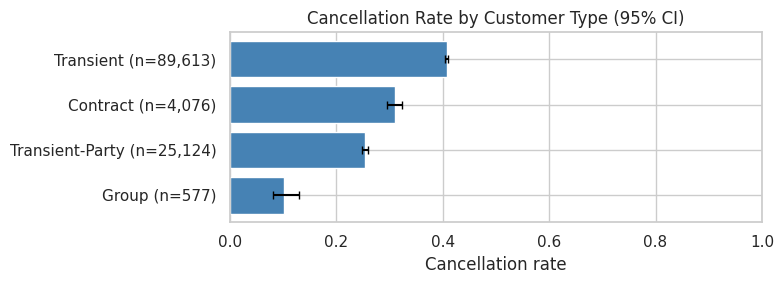

,country,bookings,cancellations,cancellation_rate,ci_low,ci_high
0,PRT,48590,27519,0.566,0.562,0.571
1,GBR,12129,2453,0.202,0.195,0.209
2,FRA,10415,1934,0.186,0.178,0.193
3,ESP,8568,2177,0.254,0.245,0.263
4,DEU,7287,1218,0.167,0.159,0.176
5,ITA,3766,1333,0.354,0.339,0.369
6,IRL,3375,832,0.247,0.232,0.261
7,BEL,2342,474,0.202,0.187,0.219
8,BRA,2224,830,0.373,0.353,0.394
9,NLD,2104,387,0.184,0.168,0.201


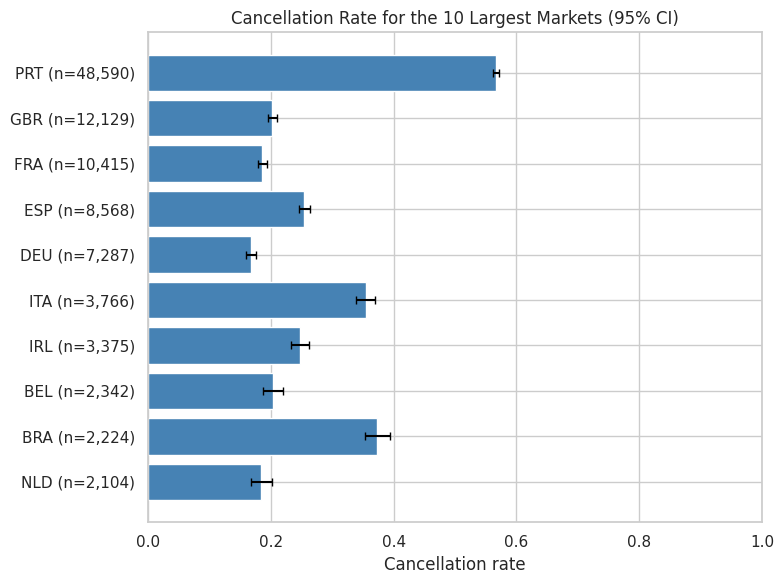

In [35]:
# Cancellation by customer type.
customer_rates = cancellation_summary(df, "customer_type")
display(customer_rates.round(3))
plot_rates(customer_rates, "customer_type", "Cancellation Rate by Customer Type (95% CI)")

# Take the 10 countries with the most bookings.
top_countries = df["country"].value_counts().head(10).index
# Cancellation rate for these 10 countries.
country_rates = cancellation_summary(df[df["country"].isin(top_countries)], "country", sort=False)
# Sort by number of bookings (biggest market first).
country_rates = country_rates.sort_values("bookings", ascending=False).reset_index(drop=True)
display(country_rates.round(3))
plot_rates(country_rates, "country", "Cancellation Rate for the 10 Largest Markets (95% CI)")

**What we found**
- **Customer type:** Transient bookings are 75.1% of the data and cancel at 40.7% (n=89,613). Contract cancels at 31.0% (n=4,076), Transient-Party at 25.4% (n=25,124) and Group at 10.2% (n=577). `customer_type` = Group (10.2%) and `market_segment` = Groups (61.1%) describe different things, so we keep both.
- **Country:** Portugal (PRT) is 40.7% of bookings and cancels at 56.6% (n=48,590). Other large markets are lower: GBR 20.2%, FRA 18.6%, DEU 16.7%, ESP 25.4%, IRL 24.7%, BEL 20.2% and NLD 18.4%. ITA (35.4%) and BRA (37.3%) are higher.
- **How to read this:** Portuguese guests cancel much more often than international guests. Before we treat country as an independent driver, 8.9b checks whether it overlaps with the Groups segment and Non Refund deposits. These are associations, not causes.

### 8.9b Overlap of country, segment and deposit type

In [36]:
# Simple label: Portugal or Other countries. We use it only for this check.
df["is_prt"] = np.where(df["country"] == "PRT", "Portugal", "Other countries")

# Does the Portugal effect stay inside each market segment?
display(cancellation_summary(df, ["is_prt", "market_segment"], min_bookings=100).round(3))
# Same check for each deposit type.
display(cancellation_summary(df, ["is_prt", "deposit_type"], min_bookings=100).round(3))

,is_prt,market_segment,bookings,cancellations,cancellation_rate,ci_low,ci_high
0,Portugal,Groups,13893,11674,0.840,0.834,0.846
1,Portugal,Offline TA/TO,11985,8121,0.678,0.669,0.686
2,Portugal,Online TA,11982,5427,0.453,0.444,0.462
3,Portugal,Aviation,105,41,0.390,0.303,0.486
4,Other countries,Online TA,44495,15312,0.344,0.340,0.349
5,Portugal,Corporate,4108,958,0.233,0.221,0.246
6,Portugal,Direct,5850,1207,0.206,0.196,0.217
7,Portugal,Complementary,665,89,0.134,0.110,0.162
8,Other countries,Direct,6756,727,0.108,0.100,0.115
9,Other countries,Aviation,132,11,0.083,0.047,0.143


,is_prt,deposit_type,bookings,cancellations,cancellation_rate,ci_low,ci_high
0,Portugal,Non Refund,14176,14140,0.997,0.996,0.998
1,Other countries,Non Refund,411,354,0.861,0.825,0.891
2,Portugal,No Deposit,34366,13356,0.389,0.383,0.394
3,Other countries,No Deposit,70275,16338,0.232,0.229,0.236
4,Other countries,Refundable,114,13,0.114,0.068,0.185


**What we found.** The Portuguese effect isn't only a mix effect. Within every segment, Portuguese bookings cancel more: Groups 84.0% against 7.1% for other countries, Offline TA/TO 67.8% against 1.6%, Online TA 45.3% against 34.4%, Corporate 23.3% against 2.9% and Direct 20.6% against 10.8%. Holding deposit type fixed shows the same: No Deposit 38.9% against 23.2%. The country gap is largest in Groups and Offline TA/TO, so country, segment and deposit type interact. In Part 2 we should use interactions or tree models, and check whether the Portuguese Groups / Offline TA/TO / Non Refund cluster is the same set of bookings.

### 8.10 ADR Distribution

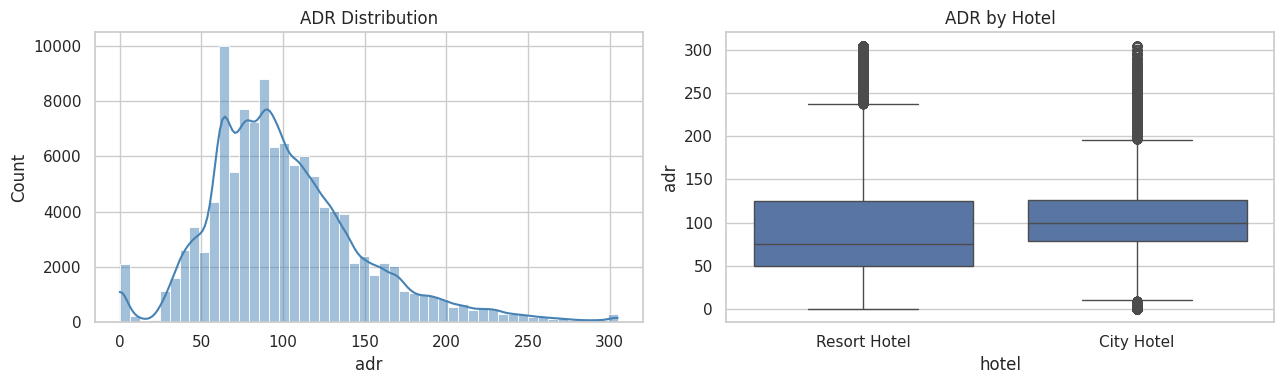

,mean,median
hotel,,
City Hotel,105.23,99.9
Resort Hotel,94.81,75.0


,high_adr,bookings,cancellations,cancellation_rate,ci_low,ci_high
0,0,83077,29987,0.361,0.358,0.364
1,1,36313,14237,0.392,0.387,0.397


In [37]:
# ADR histogram and ADR boxplot by hotel.
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df["adr"], bins=50, kde=True, color="steelblue", ax=axes[0])
axes[0].set_title("ADR Distribution")
sns.boxplot(x="hotel", y="adr", data=df, ax=axes[1])
axes[1].set_title("ADR by Hotel")
plt.tight_layout()
plt.show()

# Mean and median ADR for each hotel.
display(df.groupby("hotel")["adr"].agg(["mean", "median"]).round(2))
# Cancellation rate for high price against normal price.
display(cancellation_summary(df, "high_adr", sort=False).round(3))

**What we found.** ADR is right-skewed with a long upper tail. The City Hotel's median ADR is about 100 against about 75 for the Resort Hotel. About 2,000 bookings have ADR = 0 (probably complimentary or internal stays). We keep them, and Part 2 tests how sensitive the results are to them. The small bump at 305 is the 99.9th-percentile cap from 4.3. Price on its own has only a weak link with cancellation (36.1% vs 39.2% for the two `high_adr` groups). ADR may matter more together with other columns, and it also shows how much revenue is at risk per cancellation, which matters for the cost analysis in Part 2.

### 8.11 Same-month comparison and drift (2016 vs 2017)
The test period covers January to August only, so we have to remove seasonality before calling a change "drift". We therefore compare only January to August of 2016 and 2017.

,hotel,arrival_date_year,bookings,cancellations,cancellation_rate,ci_low,ci_high
0,City Hotel,2016,24450,9461,0.387,0.381,0.393
1,City Hotel,2017,27508,11691,0.425,0.419,0.431
2,Resort Hotel,2016,12346,3306,0.268,0.260,0.276
3,Resort Hotel,2017,13179,4054,0.308,0.300,0.316


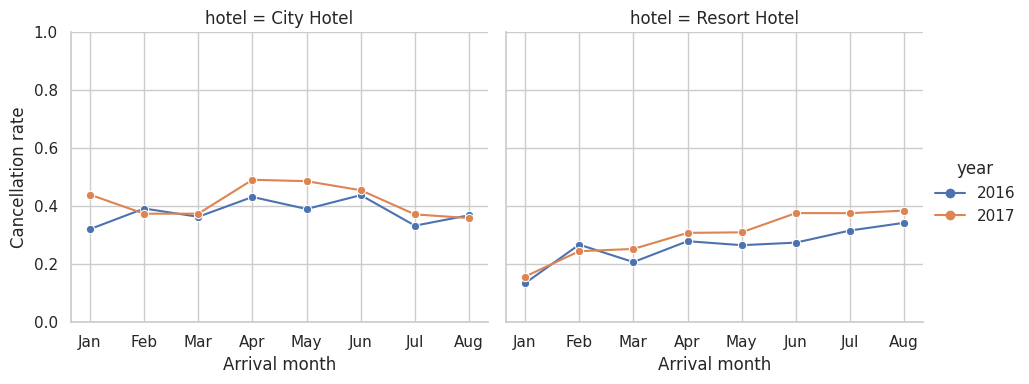

arrival_date_year,2016,2017
cancellation_rate,0.347,0.387
mean_lead_time,92.630,109.259
median_adr,91.550,107.100
share_high_adr,0.282,0.409
share_domestic,0.417,0.319
mean_total_nights,3.366,3.575
share_family,0.087,0.092


market_segment,Aviation,Complementary,Corporate,Direct,Groups,Offline TA/TO,Online TA
arrival_date_year,,,,,,,
2016,0.002,0.006,0.047,0.105,0.131,0.225,0.484
2017,0.003,0.005,0.038,0.114,0.144,0.139,0.557


deposit_type,No Deposit,Non Refund,Refundable
arrival_date_year,,,
2016,0.878,0.119,0.003
2017,0.898,0.101,0.001


In [38]:
# Keep only January to August of 2016 and 2017.
# These months exist in both years, so the season is the same.
same = df[df["arrival_date_month"].isin(month_order[:8]) & df["arrival_date_year"].isin([2016, 2017])].copy()

# Cancellation rate for each hotel in each year, with 95% CI.
yoy = (same.groupby(["hotel", "arrival_date_year"], observed=True)["is_canceled"]
           .agg(bookings="size", cancellations="sum").reset_index())
yoy["cancellation_rate"] = yoy["cancellations"] / yoy["bookings"]
yoy["ci_low"], yoy["ci_high"] = wilson_interval(yoy["cancellations"], yoy["bookings"])
display(yoy.round(3))

# Monthly cancellation rate for the line chart.
m = (same.groupby(["hotel", "arrival_date_year", "arrival_date_month"], observed=True)["is_canceled"]
         .mean().reset_index())
# Month number is needed for the x axis.
m["month_no"] = m["arrival_date_month"].astype(str).map(month_number)
m["year"] = m["arrival_date_year"].astype(str)
# Line chart: 2016 against 2017, one panel for each hotel.
g = sns.relplot(data=m, x="month_no", y="is_canceled", hue="year", col="hotel",
                kind="line", marker="o", height=4, aspect=1.2)
g.set(xticks=range(1, 9), xticklabels=[x[:3] for x in month_order[:8]], ylim=(0, 1))
g.set_axis_labels("Arrival month", "Cancellation rate")
plt.show()

# Check how the booking mix changed from 2016 to 2017
# (lead time, price, country and so on).
drift = same.groupby("arrival_date_year").agg(
    cancellation_rate=("is_canceled", "mean"), mean_lead_time=("lead_time", "mean"),
    median_adr=("adr", "median"), share_high_adr=("high_adr", "mean"),
    share_domestic=("is_domestic", "mean"), mean_total_nights=("total_nights", "mean"),
    share_family=("is_family", "mean")).T.round(3)
display(drift)
# Market segment mix by year.
display(pd.crosstab(same["arrival_date_year"], same["market_segment"], normalize="index").round(3))
# Deposit type mix by year.
display(pd.crosstab(same["arrival_date_year"], same["deposit_type"], normalize="index").round(3))

**What we found.** The cancellation rate went up in both hotels even though the booking mix changed. The mix changes may explain some of the difference, but our comparisons can't show how much each one contributes. This supports using chronological validation in Part 2.

### 8.12 Association with the target (2015–2016 only)
We compute correlation and association on the train/validation period only, so feature selection never uses 2017.

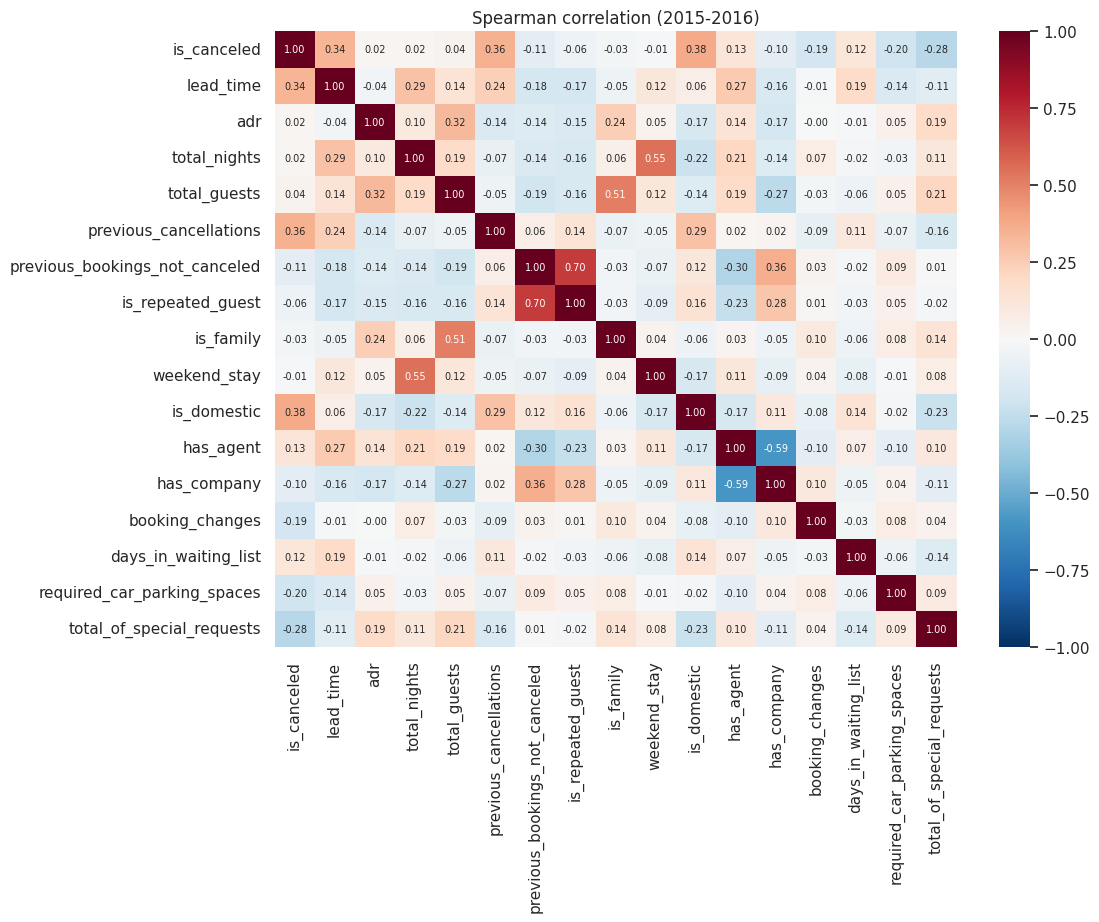

,spearman_with_target
is_domestic,0.377
previous_cancellations,0.357
lead_time,0.342
total_of_special_requests,-0.276
required_car_parking_spaces,-0.200
booking_changes,-0.185
has_agent,0.128
days_in_waiting_list,0.124
previous_bookings_not_canceled,-0.107
has_company,-0.103


,,feature_pair_corr
previous_bookings_not_canceled,is_repeated_guest,0.7


,cramers_v
deposit_type,0.514
country (top 10 + Other),0.385
market_segment,0.288
distribution_channel,0.175
hotel,0.148
customer_type,0.104
reserved_room_type,0.093
arrival_weekday,0.079
arrival_date_month,0.069
meal,0.054


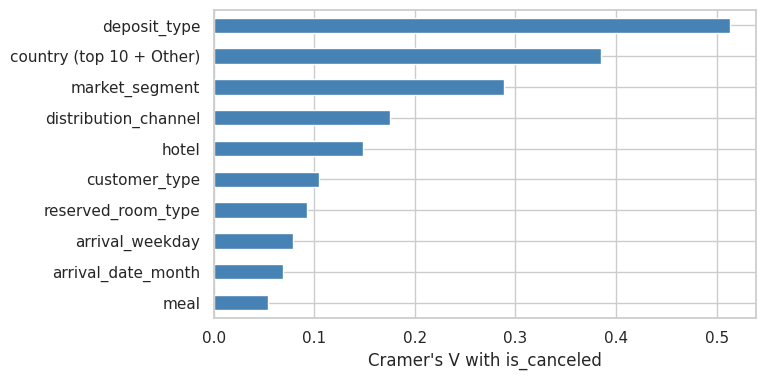

In [39]:
# Number and yes/no columns for the correlation check.
corr_cols = ["is_canceled", "lead_time", "adr", "total_nights", "total_guests", "previous_cancellations",
             "previous_bookings_not_canceled", "is_repeated_guest", "is_family", "weekend_stay",
             "is_domestic", "has_agent", "has_company", "booking_changes", "days_in_waiting_list",
             "required_car_parking_spaces", "total_of_special_requests"]
# Spearman correlation on 2015-2016 data only. It works well with skewed data.
corr = train_df[corr_cols].corr(method="spearman")

# Correlation heatmap.
plt.figure(figsize=(11, 8))
sns.heatmap(corr, cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot=True, fmt=".2f", annot_kws={"size": 7})
plt.title("Spearman correlation (2015-2016)")
plt.show()

# Correlation of each column with the target. Strongest first.
display(corr["is_canceled"].drop("is_canceled").sort_values(key=abs, ascending=False)
        .round(3).to_frame("spearman_with_target"))

# Find pairs of features which are highly correlated with each other (above 0.6).
upper = corr.where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack()
display(upper[upper.abs() > 0.6].sort_values(key=abs, ascending=False).round(2).to_frame("feature_pair_corr"))

# Cramer's V: strength of the link between two category columns.
# 0 means no link. 1 means full link.
def cramers_v(x, y):
    # Count table of each pair of values.
    ct = pd.crosstab(x, y)
    # Chi-square value.
    chi2 = chi2_contingency(ct)[0]
    n = ct.values.sum()
    r, k = ct.shape
    # Bias correction, so small tables do not give a too-high V.
    phi2 = max(0, chi2 / n - (k - 1) * (r - 1) / (n - 1))
    rc, kc = r - (r - 1) ** 2 / (n - 1), k - (k - 1) ** 2 / (n - 1)
    return float(np.sqrt(phi2 / min(kc - 1, rc - 1)))

# For country we keep the top 10 and put the rest in Other.
top10 = train_df["country"].value_counts().head(10).index
# Category columns to test.
cats = {c: train_df[c].astype(str) for c in ["hotel", "arrival_date_month", "arrival_weekday", "meal",
        "market_segment", "distribution_channel", "reserved_room_type", "customer_type", "deposit_type"]}
cats["country (top 10 + Other)"] = train_df["country"].where(train_df["country"].isin(top10), "Other")
# Cramer's V of each category column with the target.
cv = pd.Series({k: cramers_v(v, train_df["is_canceled"]) for k, v in cats.items()}).sort_values()
# Bar chart of Cramer's V.
cv.plot.barh(figsize=(7, 4), color="steelblue")
display(cv.sort_values(ascending=False).round(3).to_frame("cramers_v"))
plt.xlabel("Cramer's V with is_canceled")
plt.show()

**What we found (2015–2016 only).** For categorical columns we use Cramér's V. `deposit_type` has the strongest association with cancellation (V = 0.514), then `country` (V = 0.385) and `market_segment` (V = 0.288). `distribution_channel` (V = 0.175) and `hotel` (V = 0.148) are weaker. `customer_type`, `reserved_room_type`, `arrival_weekday`, `arrival_date_month` and `meal` are all weak (V below 0.11). `deposit_type` ranks first mainly because of the Non Refund pattern from Section 8.7b, so Part 2 tests it both with and without this column.

### 8.13 Remaining variables
We check the columns we haven't profiled yet against cancellation, using the same format of rate, n and 95% interval.

,nights_group,bookings,cancellations,cancellation_rate,ci_low,ci_high
0,0,715,35,0.049,0.035,0.067
1,1,21020,5271,0.251,0.245,0.257
2,2-3,54719,23514,0.430,0.426,0.434
3,4-7,37679,13525,0.359,0.354,0.364
4,8-14,4818,1636,0.340,0.326,0.353
5,15+,439,243,0.554,0.507,0.599


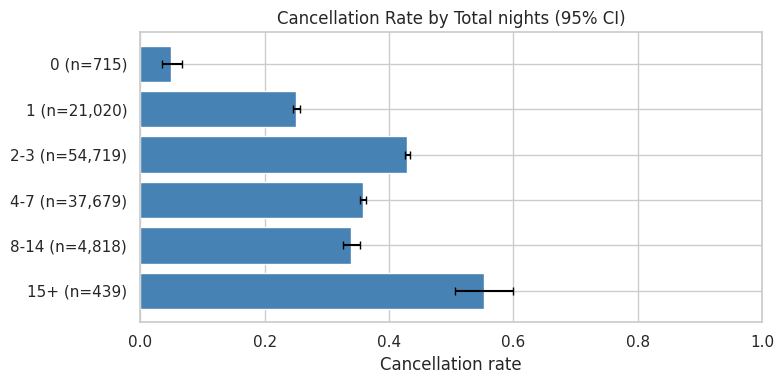

,meal,bookings,cancellations,cancellation_rate,ci_low,ci_high
0,BB,92310,34510,0.374,0.371,0.377
1,FB,798,478,0.599,0.565,0.632
2,HB,14463,4984,0.345,0.337,0.352
3,SC,11819,4252,0.360,0.351,0.368


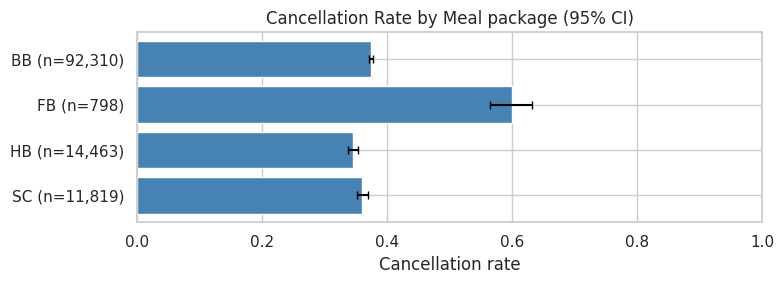

,distribution_channel,bookings,cancellations,cancellation_rate,ci_low,ci_high
0,Corporate,6677,1474,0.221,0.211,0.231
1,Direct,14645,2557,0.175,0.169,0.181
2,GDS,193,37,0.192,0.142,0.253
3,TA/TO,97870,40152,0.410,0.407,0.413


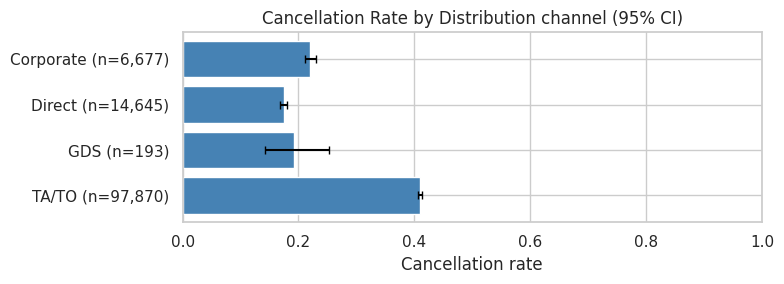

,reserved_room_type,bookings,cancellations,cancellation_rate,ci_low,ci_high
0,A,85994,33630,0.391,0.388,0.394
1,B,1118,368,0.329,0.302,0.357
2,C,932,308,0.330,0.301,0.361
3,D,19201,6102,0.318,0.311,0.324
4,E,6535,1914,0.293,0.282,0.304
5,F,2897,880,0.304,0.287,0.321
6,G,2094,763,0.364,0.344,0.385
7,H,601,245,0.408,0.369,0.447


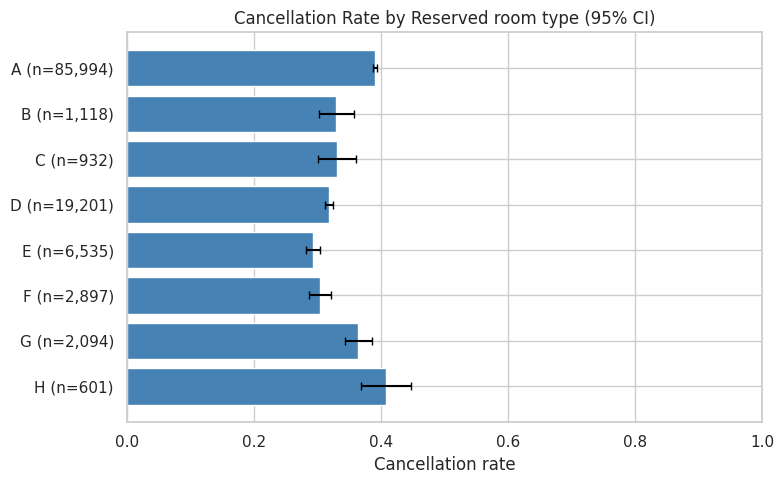

,booking_changes_group,bookings,cancellations,cancellation_rate,ci_low,ci_high
0,0,101314,41391,0.409,0.406,0.412
1,1,12701,1807,0.142,0.136,0.148
2,2,3805,766,0.201,0.189,0.214
3,3+,1570,260,0.166,0.148,0.185


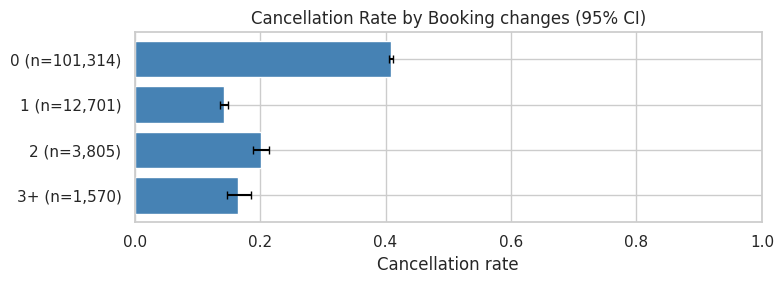

,has_previous_cancel,bookings,cancellations,cancellation_rate,ci_low,ci_high
0,0,112906,38282,0.339,0.336,0.342
1,1,6484,5942,0.916,0.909,0.923


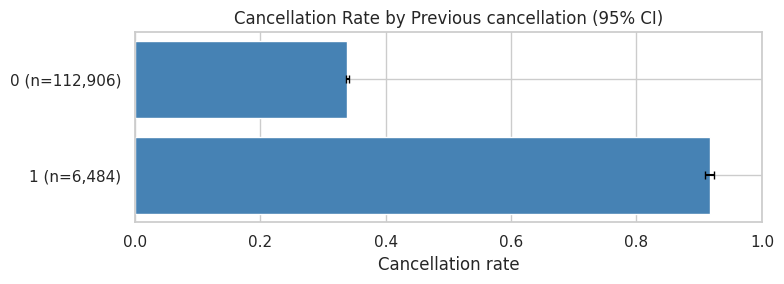

,was_waitlisted,bookings,cancellations,cancellation_rate,ci_low,ci_high
0,0,115692,41865,0.362,0.359,0.365
1,1,3698,2359,0.638,0.622,0.653


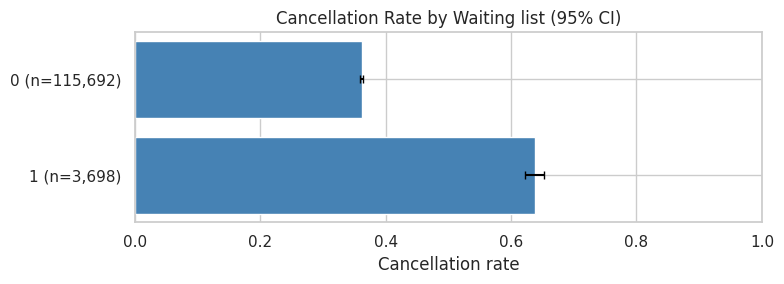

,arrival_weekday,bookings,cancellations,cancellation_rate,ci_low,ci_high
0,Monday,18171,6195,0.341,0.334,0.348
1,Tuesday,13999,4600,0.329,0.321,0.336
2,Wednesday,16139,5831,0.361,0.354,0.369
3,Thursday,19254,7927,0.412,0.405,0.419
4,Friday,19631,7978,0.406,0.400,0.413
5,Saturday,18055,7129,0.395,0.388,0.402
6,Sunday,14141,4564,0.323,0.315,0.331


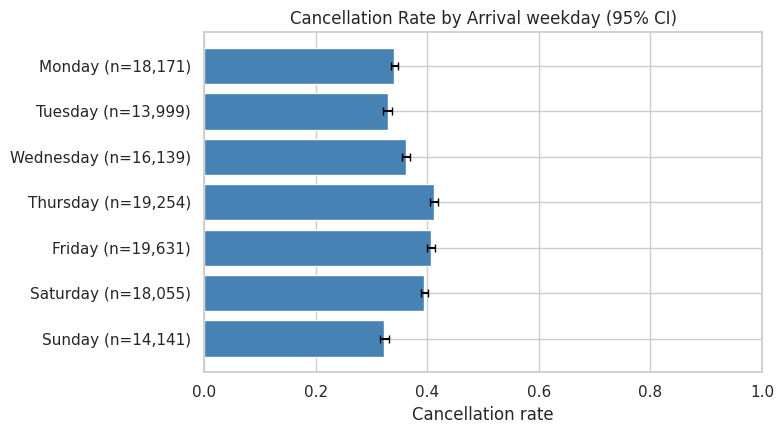

,has_agent,bookings,cancellations,cancellation_rate,ci_low,ci_high
0,0,16340,4030,0.247,0.240,0.253
1,1,103050,40194,0.390,0.387,0.393


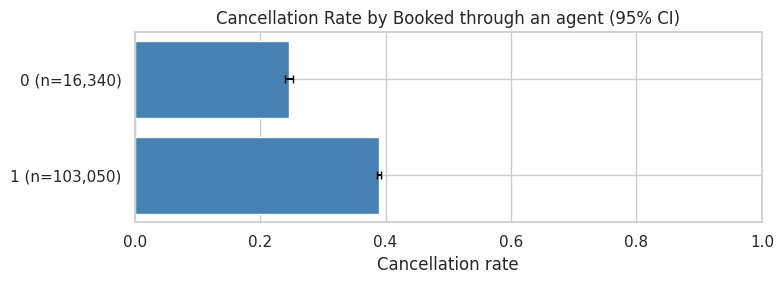

In [40]:
# Remaining columns to check. Each item is (column name, chart title).
extra = [("nights_group", "Total nights"), ("meal", "Meal package"),
         ("distribution_channel", "Distribution channel"), ("reserved_room_type", "Reserved room type"),
         ("booking_changes_group", "Booking changes"), ("has_previous_cancel", "Previous cancellation"),
         ("was_waitlisted", "Waiting list"), ("arrival_weekday", "Arrival weekday"),
         ("has_agent", "Booked through an agent")]
# For each column: show the table and draw the chart.
for col, title in extra:
    s = cancellation_summary(df, col, min_bookings=30, sort=False)
    display(s.round(3))
    plot_rates(s, col, f"Cancellation Rate by {title} (95% CI)")

**What we found**
- **Total nights:** cancellation is lowest for stays of 0 nights (4.9%) and 1 night (25.1%) and rises with longer stays, reaching 55.4% for 15 or more nights. That last group has only 439 bookings, though.
- **Meal package:** Full Board (FB) has the highest rate (59.9%), against Bed & Breakfast (BB) at 37.4%, Self Catering (SC) at 36.0% and Half Board (HB) at 34.5%. Full Board has only 798 bookings, so we shouldn't read too much into it.
- **Distribution channel:** Travel Agents/Tour Operators (TA/TO) have the highest rate (41.0%), then Corporate (22.1%), GDS (19.2%) and Direct (17.5%). TA/TO also makes up most of the bookings, which makes this pattern especially relevant.

Overall, cancellation differs by stay length, meal package and distribution channel. These columns may help in Part 2, and we will judge them with the chronological validation setup.

In [41]:
# Who are the bookings with a previous cancellation? Are they mostly Portuguese group bookings?
prev = df[df["has_previous_cancel"] == 1]
print(prev["market_segment"].value_counts(normalize=True).round(3).head(4).to_dict())
print(prev["deposit_type"].value_counts(normalize=True).round(3).to_dict())
print("Portuguese share:", round((prev["country"] == "PRT").mean(), 3))

{'Groups': 0.516, 'Offline TA/TO': 0.259, 'Online TA': 0.095, 'Corporate': 0.089}
{'Non Refund': 0.562, 'No Deposit': 0.438}
Portuguese share: 0.951


**What we found.** Bookings with a previous cancellation are mostly Groups (51.6%) and Offline TA/TO (25.9%), and 56.2% have a Non Refund deposit. 95.1% are Portuguese. So `previous_cancellations` likely overlaps with the Portuguese group and agent cluster seen in 8.7b and 8.9b, and may not be a fully independent signal.

## 9. Part 1 Summary

In Part 1 we cleaned the data, prepared it, built new features, ran the leakage audit and explored the cancellation patterns.

The dataset has **119,390 hotel bookings** and an overall cancellation rate of **37.04%**. We handled the missing values and the unusual ADR values, and we kept the duplicate rows.

We created new features that describe booking behaviour. The leakage audit separated the reliable columns from the ambiguous and outcome-related ones.

The EDA showed these main patterns:
- City Hotel bookings are cancelled more often than Resort Hotel bookings.
- Longer lead times go with more cancellations.
- Group bookings and Portuguese bookings are cancelled more often.
- Cancellation patterns differ across booking channels, meal types and stay lengths.
- Cancellation rates went up in both hotels from 2016 to 2017.

Finally, we fitted the preprocessing pipeline on **2015–2016 data** and kept **2017 for testing**, to support chronological validation.

**Part 1 is complete.** Part 2 trains and tunes the models, compares them, evaluates them on the 2017 test set and looks for the most useful predictors of cancellation.

In [42]:
# Final checks for Part 1. If any check fails, the code stops with an error.
assert df.shape[0] == 119390 and int(df["is_canceled"].sum()) == 44224
assert set(df["split"].unique()) == {"train_val", "test"}
assert not {"reservation_status", "reservation_status_date", "assigned_room_type"} & set(df.columns)
print("Notebook executed top to bottom without errors.")

Notebook executed top to bottom without errors.


In [43]:
# Save the cleaned data in a CSV file, so we can use it again later.
df.to_csv("hotel_bookings_cleaned.csv", index=False)
print("Saved hotel_bookings_cleaned.csv", df.shape)

Saved hotel_bookings_cleaned.csv (119390, 46)


# Predicting Booking Cancellations at Reservation Time
### Part 2: Model Training, Tuning, Evaluation and Final Pipeline

**Course:** Data Science Tools and Technologies | **Instructor:** Dr. Asma Ahmed

**Team:** Nurmeen Shahid (26L-8010) and Ayesha Mazher (26L-8005)

In Part 1 we cleaned the hotel booking data, checked which columns leak the answer, built features and did the EDA.

Part 2 covers the following 6 parts:
1. Rebuild the cleaned data and define six feature sets (the strict main set, three variations and two leakage benchmarks), so Part 2 can run on its own.
2. Set up the time-based validation: 2017 stays untouched as the test period, and 2015-2016 is split into three rolling-origin folds.
3. Train the baselines (prior rate, one rule, logistic regression) and the models (L1 logistic, random forest, XGBoost), tune them on the rolling folds with PR-AUC, and choose the final model on validation only.
4. Measure how much leakage and the split design change the score: the feature-set comparison (RQ1), the random split against the time split, the score for each test month, and a check with duplicate rows removed (RQ2).
5. Turn the risk scores into decisions: compare doing nothing, acting on every booking and acting above a cost-based threshold, test how sensitive this is to the cost assumptions, and build the risk tiers (RQ3).
6. Find the factors behind cancellation with SHAP, check that they are stable over time and across hotels (RQ4), then save the final pipeline, which scores new bookings into risk tiers, and report the final results and limits.


Our research questions from the proposal:

1. How much of the model score disappears when outcome-revealing columns are removed?
2. How big is the gap between a random split and a split by time?
3. How much money can the model save compared with doing nothing or acting on every booking?
4. Which factors drive cancellation, are they stable over time, and does a model move from one hotel to the other?

Rules we follow all the way: 2017 is the test set and we do not use it to make any choice. All scaling and encoding is fitted on training data only. The main metric is PR-AUC for the cancelled class.

## Part 2, 1. Setup
We install SHAP (used for explaining the model) and import the libraries.

In [44]:
# Install xgboost and shap. The -q option keeps the output short.
%pip install -q xgboost shap

In [45]:
# Libraries for Part 2.
# Some imports are repeated from Part 1, so Part 2 can also run alone.
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from pathlib import Path

# scikit-learn tools: pipeline, preprocessing, models, search and metrics.
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV, GridSearchCV, train_test_split
from sklearn.inspection import permutation_importance
from sklearn.calibration import calibration_curve
from sklearn.metrics import (average_precision_score, roc_auc_score, f1_score, brier_score_loss,
                             precision_recall_curve, precision_score, recall_score,
                             ConfusionMatrixDisplay)
# XGBoost model, and SHAP for explaining the model.
from xgboost import XGBClassifier, DMatrix
import shap

# Basic settings for charts and tables.
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 4)
pd.set_option("display.width", 200)

# Fixed seed for repeatable results.
RANDOM_STATE = 42

## Part 2, 2. Loading and cleaning the data
This is the same cleaning we did in Part 1. We repeat it here in short so that this notebook can run on its own.

- Missing agent and company are filled with 0 (no agent or company), missing country with "Unknown", missing children with 0.
- Meal types "SC" and "Undefined" are merged.
- One negative ADR is replaced, and very high ADR values are capped. The cap is learned from 2015 and 2016 only.
- We add the same new columns as before (total nights, total guests, family flag and so on).
- The data paper (Antonio et al., 2019) says that NULL in agent and company means "not applicable" (no agent, no company) and is not a real missing value. So filling with 0 is the correct way.
- The paper also shows that in IsCanceled the no-shows are counted as cancelled, so our target means "the guest did not stay".
- We also keep a booking value (ADR times nights) which we use only in the cost analysis, and a flag for duplicate rows which we use only for one check.

In [46]:
# Load the raw data again (same as Part 1).
import kagglehub

path = kagglehub.dataset_download("jessemostipak/hotel-booking-demand")
df_raw = pd.read_csv(Path(path) / "hotel_bookings.csv", na_values=["NULL"])
print("Rows and columns:", df_raw.shape)
print("Cancellation rate:", round(df_raw["is_canceled"].mean(), 4))

Using Colab cache for faster access to the 'hotel-booking-demand' dataset.
Rows and columns: (119390, 32)
Cancellation rate: 0.3704


In [47]:
# Repeat the same cleaning as Part 1, in short. This keeps Part 2 independent.
df = df_raw.copy()

# Month names and numbers, to make the arrival date.
month_order = ["January", "February", "March", "April", "May", "June", "July",
               "August", "September", "October", "November", "December"]
month_number = {m: i + 1 for i, m in enumerate(month_order)}

# Make a real date column.
df["arrival_date"] = pd.to_datetime(dict(
    year=df["arrival_date_year"],
    month=df["arrival_date_month"].map(month_number),
    day=df["arrival_date_day_of_month"]))

# missing values
df["children"] = df["children"].fillna(0)
df["country"] = df["country"].fillna("Unknown")
df["agent"] = df["agent"].fillna(0)
df["company"] = df["company"].fillna(0)

# SC and Undefined both mean no meal package
df["meal"] = df["meal"].replace({"Undefined": "SC"})

# adr: negative value and extreme values, using 2015-2016 only
# old is True for 2015-2016 rows. We learn the ADR limits from these rows only.
old = df["arrival_date_year"] < 2017
df.loc[df["adr"] < 0, "adr"] = df.loc[old & (df["adr"] >= 0), "adr"].median()
adr_cap = df.loc[old, "adr"].quantile(0.999)
df["adr"] = df["adr"].clip(upper=adr_cap)

# new columns, same as phase 1
df["total_nights"] = df["stays_in_week_nights"] + df["stays_in_weekend_nights"]
df["total_guests"] = df["adults"] + df["children"] + df["babies"]
df["is_family"] = ((df["children"] > 0) | (df["babies"] > 0)).astype(int)
df["weekend_stay"] = (df["stays_in_weekend_nights"] > 0).astype(int)
df["has_agent"] = (df["agent"] > 0).astype(int)
df["has_company"] = (df["company"] > 0).astype(int)
df["arrival_weekday"] = df["arrival_date"].dt.day_name()

# used later only for the cost analysis and the duplicate check
# booking_value = price per night x number of nights. We use it only in the cost analysis.
df["booking_value"] = df["adr"] * df["total_nights"]
# True for rows which are exact copies of an earlier row.
df["is_duplicate"] = df_raw.duplicated()

print("ADR cap:", round(adr_cap, 1), "| rows:", len(df))

ADR cap: 305.0 | rows: 119390


## Part 2, 3. Feature sets
From the leakage audit in Part 1 we have these sets of columns:

- **A strict:** only things known when the booking is made. This is our main set.
- **A without adr:** A, but without the price, because ADR can be updated after booking.
- **A plus deposit:** A with deposit type. In Part 1 we saw that Non Refund bookings are almost 100% cancelled, which looks like a recording problem, so we test it separately.
- **A paper-safe:** A without the columns that the data paper warns about. The paper says the hotel often does not know the real country until check-in, and that guests often change the number of persons, the nights and the meal at check-in or during the stay. Because of this, the paper shows that these columns look different for cancelled and non-cancelled bookings. So this set drops country, meal, total guests, family flag, total nights and weekend stay.
- **B plus ambiguous:** A with four columns that may be filled in after the booking (booking changes, days in waiting list, parking spaces, special requests).
- **C leaky:** B plus assigned room type and reservation status. This is on purpose a wrong set, only to show how much leakage can fake a good result.

The choice of the main set A is made by the timing rule from Part 1, not by which set gives the best score. The paper says all values were taken as they were one day before arrival, so set A is a fair main set, and "A paper-safe" tells us how much we depend on the columns the paper warns about.

The preprocessing is the same as Part 1: median fill, log of skewed columns, scaling, and one-hot encoding. It sits inside the pipeline, so it is fitted only on the training part every time.

In [48]:
# Column groups. These are the same as set A (strict) in Part 1.
NUM = ["lead_time", "adr", "total_nights", "total_guests",
       "previous_cancellations", "previous_bookings_not_canceled"]
BIN = ["is_repeated_guest", "is_family", "weekend_stay", "has_agent", "has_company"]
CAT = ["hotel", "arrival_date_month", "arrival_weekday", "meal", "country",
       "market_segment", "distribution_channel", "reserved_room_type", "customer_type"]

# Columns which may be filled after booking.
AMBIGUOUS = ["booking_changes", "days_in_waiting_list",
             "required_car_parking_spaces", "total_of_special_requests"]
# Columns which give away the answer. For the leakage test only.
LEAKY = ["assigned_room_type", "reservation_status"]

# Six feature sets. A strict is the main one. The others are for checks.
feature_sets = {
    "A strict":          dict(num=NUM,             bin=BIN, cat=CAT),
    "A without adr":     dict(num=[c for c in NUM if c != "adr"], bin=BIN, cat=CAT),
    "A plus deposit":    dict(num=NUM,             bin=BIN, cat=CAT + ["deposit_type"]),
    "A paper-safe":      dict(num=["lead_time", "adr", "previous_cancellations", "previous_bookings_not_canceled"],
                              bin=["is_repeated_guest", "has_agent", "has_company"],
                              cat=["hotel", "arrival_date_month", "arrival_weekday", "market_segment",
                                   "distribution_channel", "reserved_room_type", "customer_type"]),
    "B plus ambiguous":  dict(num=NUM + AMBIGUOUS, bin=BIN, cat=CAT),
    "C leaky":           dict(num=NUM + AMBIGUOUS, bin=BIN, cat=CAT + LEAKY),
}

# Join all column names of a set into one list.
def columns_of(fs):
    return fs["num"] + fs["bin"] + fs["cat"]

# Same preprocessing as Part 1: fill missing, log, scale and one-hot encode.
def make_preprocessor(num, bin_, cat):
    log_cols = [c for c in ("lead_time", "adr", "days_in_waiting_list") if c in num]
    other = [c for c in num if c not in log_cols]
    return ColumnTransformer([
        ("log_scale", Pipeline([("imp", SimpleImputer(strategy="median")),
                                ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
                                ("sc", StandardScaler())]), log_cols),
        ("scale", Pipeline([("imp", SimpleImputer(strategy="median")),
                            ("sc", StandardScaler())]), other),
        ("bin", "passthrough", bin_),
        ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=100, sparse_output=False), cat),
    ])

# Pipeline = preprocessing + model.
# So preprocessing is always fitted on training data only.
def make_pipe(fs, model):
    return Pipeline([("prep", make_preprocessor(fs["num"], fs["bin"], fs["cat"])), ("model", model)])

# Show how many columns each set has.
for name, fs in feature_sets.items():
    print(f"{name:18s} {len(columns_of(fs))} columns")

A strict           20 columns
A without adr      19 columns
A plus deposit     21 columns
A paper-safe       14 columns
B plus ambiguous   24 columns
C leaky            26 columns


## Part 2, 4. Data splitting
We split the data by time, as promised in the proposal.

- **Test set:** all 2017 bookings (40,687 rows). We do not use them for any choice or tuning.
- **Train and validation:** 2015 and 2016 bookings (78,703 rows).
- **Validation method:** rolling origin. We train on everything before a date and validate on the next 3 months. This is done three times, so every validation fold is later than its training data.

The split is done by arrival date, as in the proposal. A small limit of this: a booking made in 2016 for an arrival in 2017 is in the test set, even though it was made early. We accept this.

Note that the three validation folds cover different seasons (spring, summer, autumn), so a fold score also depends on the season.

In [49]:
# Train/validation = 2015-2016. Test = 2017 (kept aside).
train_val = df[df["arrival_date_year"] < 2017].reset_index(drop=True)   # 2015 and 2016
test = df[df["arrival_date_year"] == 2017].reset_index(drop=True)         # 2017, kept aside
# Targets (0 or 1).
y_tv = train_val["is_canceled"]
y_test = test["is_canceled"]

# rolling origin folds: train on everything before, validate on the next 3 months
# Each fold: train on all earlier months, then validate on the next 3 months.
fold_dates = [("2016-04-01", "2016-07-01"),
              ("2016-07-01", "2016-10-01"),
              ("2016-10-01", "2017-01-01")]
# cv_folds keeps the row positions of every train and validation part.
cv_folds = []
rows = []
# Build the three folds.
for k, (start, end) in enumerate(fold_dates, start=1):
    # Training rows: everything before the start date.
    tr = np.where(train_val["arrival_date"] < start)[0]
    # Validation rows: the next 3 months.
    va = np.where((train_val["arrival_date"] >= start) & (train_val["arrival_date"] < end))[0]
    cv_folds.append((tr, va))
    rows.append([k, f"Jul 2015 to {pd.Timestamp(start).strftime('%b %Y')}", len(tr), y_tv.iloc[tr].mean(),
                 f"{pd.Timestamp(start).strftime('%b')} to {(pd.Timestamp(end) - pd.Timedelta(days=1)).strftime('%b %Y')}",
                 len(va), y_tv.iloc[va].mean()])

# Show a table of the three folds.
print("Train/validation (2015-2016):", len(train_val), "| Test (2017):", len(test))
pd.DataFrame(rows, columns=["fold", "training period", "train rows", "train cancel rate",
                            "validation period", "val rows", "val cancel rate"]).round(3)

Train/validation (2015-2016): 78703 | Test (2017): 40687


,fold,training period,train rows,train cancel rate,validation period,val rows,val cancel rate
0,1,Jul 2015 to Apr 2016,32959,0.349,Apr to Jun 2016,16198,0.375
1,2,Jul 2015 to Jul 2016,49157,0.358,Jul to Sep 2016,15029,0.356
2,3,Jul 2015 to Oct 2016,64186,0.357,Oct to Dec 2016,14517,0.382


## Part 2, 5. Metrics and helper functions
- **PR-AUC (average precision):** our main metric. It looks at how well the model puts the cancelled bookings at the top. A model with no skill gets the cancel rate as its score (about 0.37 to 0.39 here).
- **ROC-AUC:** the second ranking score. A model with no skill gets 0.5.
- **F1:** uses a cut-off. We pick the cut-off on the validation predictions (the best F1 there), and then use it on the test set without changing.
- **Brier score:** checks if the probabilities are honest. Lower is better.

PR-AUC is the main metric because of the study by Gaudreault and Branco (2024), which we used in the proposal. They found that PR-curve based metrics agree most with the overall ranking of models, and that ranking metrics are less affected by noise in the probabilities.

We do not use accuracy because always saying "not cancelled" already gives about 63%.

`rolling_cv` trains on each training fold and predicts the next validation fold. `evaluate` then gives CV scores, the cut-off, and one look at the test set.

In [50]:
# Calculates the four metrics: PR-AUC, ROC-AUC, F1 and Brier.
def get_metrics(y, p, thr=0.5):
    # Change probability into 0 or 1 using the threshold.
    pred = (p >= thr).astype(int)
    return {"PR-AUC": average_precision_score(y, p),
            "ROC-AUC": roc_auc_score(y, p),
            "F1": f1_score(y, pred),
            "Brier": brier_score_loss(y, p)}

# Finds the threshold which gives the best F1 score.
def best_f1_threshold(y, p):
    # Precision and recall at many thresholds.
    prec, rec, thr = precision_recall_curve(y, p)
    # F1 for each threshold. The tiny number avoids division by zero.
    f1 = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-12)
    return thr[np.argmax(f1)]

# Rolling validation: train on the training part, predict the validation part after it.
def rolling_cv(pipe, cols):
    """Fit on each training fold, predict the validation fold after it."""
    X = train_val[cols]
    # Lists to keep the scores and the predictions.
    scores, idx, preds = [], [], []
    # Loop over the three folds.
    for tr, va in cv_folds:
        # clone() gives a fresh copy of the model for each fold.
        m = clone(pipe).fit(X.iloc[tr], y_tv.iloc[tr])
        p = m.predict_proba(X.iloc[va])[:, 1]
        scores.append(average_precision_score(y_tv.iloc[va], p))
        idx.append(va)
        preds.append(p)
    return scores, np.concatenate(idx), np.concatenate(preds)

# Dictionary to store the results of every model.
results = {}     # one entry per model, filled below

# Runs the full check for one model: CV score, threshold and one test score.
def evaluate(name, pipe, cols):
    """CV scores, threshold from validation, and one look at the 2017 test set."""
    # Step 1: rolling validation. oof means out-of-fold predictions.
    scores, oof_idx, oof_p = rolling_cv(pipe, cols)
    # Step 2: choose the threshold on validation predictions only.
    thr = best_f1_threshold(y_tv.iloc[oof_idx], oof_p)
    cv_brier = brier_score_loss(y_tv.iloc[oof_idx], oof_p)
    # Step 3: train on all 2015-2016 data and predict the 2017 test set.
    fitted = clone(pipe).fit(train_val[cols], y_tv)
    p_test = fitted.predict_proba(test[cols])[:, 1]
    # Save everything for later use.
    results[name] = dict(pipe=fitted, cols=cols, cv_scores=scores, cv_brier=cv_brier, oof_idx=oof_idx, oof_p=oof_p,
                         thr=thr, p_test=p_test, **get_metrics(y_test, p_test, thr))
    print(f"{name:22s} CV PR-AUC {np.mean(scores):.3f} | Test PR-AUC {results[name]['PR-AUC']:.3f}")

## Part 2, 6. Baselines
Three simple baselines from the proposal:

1. **Prior rate:** every booking gets the same score, the cancel rate in training.
2. **One rule:** say "cancel" when lead time is more than some days. The days are picked on training data.
3. **Logistic regression:** a simple model on the strict reservation-time features.

In [51]:
# 1. prior rate: every booking gets the same score (the training cancel rate)
# A constant score gives a PR-AUC equal to the cancel rate of that fold.
cv_scores = [y_tv.iloc[va].mean() for tr, va in cv_folds]      # PR-AUC of a constant score = cancel rate
# Same score for every test booking.
p_const = np.full(len(test), y_tv.mean())
results["Prior rate"] = dict(cv_scores=cv_scores, thr=0.5, p_test=p_const,
                             **get_metrics(y_test, p_const, 0.5))
results["Prior rate"]["F1"] = 0.0      # the majority class is "not cancelled", so it never predicts a cancellation

# 2. one rule: cancel if lead time is above a cut-off picked on the training data
# Try some lead time cut-offs. Pick the one with the best F1.
def pick_lead_cutoff(d):
    best_cut, best_f1 = None, -1
    for cut in [7, 14, 30, 45, 60, 90, 120, 150, 180, 270]:
        # Rule: lead time above the cut-off means cancel.
        f1 = f1_score(d["is_canceled"], (d["lead_time"] > cut).astype(int))
        if f1 > best_f1:
            best_cut, best_f1 = cut, f1
    return best_cut

# Pick the cut-off again inside each fold, using training rows only.
cv_scores = []
for tr, va in cv_folds:
    cut = pick_lead_cutoff(train_val.iloc[tr])
    cv_scores.append(average_precision_score(y_tv.iloc[va], (train_val.iloc[va]["lead_time"] > cut).astype(int)))
# Final cut-off from all 2015-2016 data.
cut = pick_lead_cutoff(train_val)
# Rule prediction for the test set (0 or 1).
p_rule = (test["lead_time"] > cut).astype(float).values
results["One rule (lead time)"] = dict(cv_scores=cv_scores, thr=0.5, p_test=p_rule, **get_metrics(y_test, p_rule, 0.5))
print("Rule: predict cancel when lead time is more than", cut, "days")

# 3. logistic regression on the strict reservation-time features
# Column list of set A (strict).
colsA = columns_of(feature_sets["A strict"])
# Train and test the logistic regression.
evaluate("Logistic regression", make_pipe(feature_sets["A strict"],
         LogisticRegression(max_iter=1000)), colsA)

Rule: predict cancel when lead time is more than 14 days
Logistic regression    CV PR-AUC 0.770 | Test PR-AUC 0.768


The prior rate model has no skill, as expected (PR-AUC is just the cancel rate). The one rule picked 14 days. It has a good looking F1 (0.608) only because it calls most bookings cancelled, and its Brier score is very bad (0.466), so it is not a usable model. Logistic regression is already strong: PR-AUC of 0.770 on validation and 0.768 on the test set. Any better model has to beat this.

## Part 2, 7. Models and tuning
We try three more models. All are tuned with the same rolling validation folds, scoring on PR-AUC.

- **Regularised logistic regression (L1):** the same simple model, but the L1 penalty can switch off useless columns. We tune the strength C.
- **Random forest:** many trees, good with mixed data and interactions. We tune depth, leaf size and number of trees.
- **XGBoost:** boosted trees. We first run it with default settings, and then tune it, so we can see what tuning gives.

We use small random searches so that the notebook runs in reasonable time. We did not use class weights. The cancel rate is about 37%, which is not very imbalanced, and we need honest probabilities for the cost part later.

In [52]:
# regularised logistic regression: L1 penalty, tune the strength C
# Tune C of the L1 logistic regression.
# Smaller C means a stronger penalty. We score with PR-AUC on our rolling folds.
search_lr = GridSearchCV(
    make_pipe(feature_sets["A strict"], LogisticRegression(penalty="l1", solver="liblinear", tol=1e-3, max_iter=200)),
    param_grid={"model__C": [0.01, 0.03, 0.1, 0.3]},
    scoring="average_precision", cv=cv_folds, n_jobs=1)
# Run the search.
search_lr.fit(train_val[colsA], y_tv)
# Show the best C.
print("Best C:", search_lr.best_params_)
# Check the tuned model in the same way as the other models.
evaluate("Logistic L1 (tuned)", search_lr.best_estimator_, colsA)

Best C: {'model__C': 0.1}
Logistic L1 (tuned)    CV PR-AUC 0.770 | Test PR-AUC 0.768


In [53]:
# random forest
# Values which the search can try for the random forest.
rf_space = {"model__n_estimators": [150, 250],
            "model__max_depth": [10, 14, 18],
            "model__min_samples_leaf": [3, 10, 30],
            "model__max_features": ["sqrt", 0.3]}
# Random search tries only 6 combinations. This keeps the run time short.
search_rf = RandomizedSearchCV(
    make_pipe(feature_sets["A strict"], RandomForestClassifier(n_jobs=-1, random_state=RANDOM_STATE)),
    param_distributions=rf_space, n_iter=6, scoring="average_precision",
    cv=cv_folds, random_state=RANDOM_STATE, n_jobs=1)
search_rf.fit(train_val[colsA], y_tv)
print("Best parameters:", search_rf.best_params_)
print("Best CV PR-AUC:", round(search_rf.best_score_, 4))
evaluate("Random forest (tuned)", search_rf.best_estimator_, colsA)

Best parameters: {'model__n_estimators': 250, 'model__min_samples_leaf': 3, 'model__max_features': 'sqrt', 'model__max_depth': 14}
Best CV PR-AUC: 0.795
Random forest (tuned)  CV PR-AUC 0.795 | Test PR-AUC 0.787


In [54]:
# xgboost: first with default settings, then tuned
# XGBoost with default settings. We use it to see how much tuning helps.
xgb_default = XGBClassifier(eval_metric="logloss", tree_method="hist", n_jobs=-1, random_state=RANDOM_STATE)
evaluate("XGBoost (default)", make_pipe(feature_sets["A strict"], xgb_default), colsA)

# Values which the search can try for XGBoost.
xgb_space = {"model__n_estimators": [150, 300, 500],
             "model__max_depth": [3, 4, 6, 8],
             "model__learning_rate": [0.03, 0.05, 0.1],
             "model__subsample": [0.7, 0.9],
             "model__colsample_bytree": [0.6, 0.8],
             "model__min_child_weight": [1, 5, 10]}
# Random search with 12 combinations.
search_xgb = RandomizedSearchCV(
    make_pipe(feature_sets["A strict"], XGBClassifier(eval_metric="logloss", tree_method="hist",
                                                      n_jobs=-1, random_state=RANDOM_STATE)),
    param_distributions=xgb_space, n_iter=12, scoring="average_precision",
    cv=cv_folds, random_state=RANDOM_STATE, n_jobs=1)
search_xgb.fit(train_val[colsA], y_tv)
print("Best parameters:", search_xgb.best_params_)
print("Best CV PR-AUC:", round(search_xgb.best_score_, 4))
evaluate("XGBoost (tuned)", search_xgb.best_estimator_, colsA)

XGBoost (default)      CV PR-AUC 0.771 | Test PR-AUC 0.781
Best parameters: {'model__subsample': 0.7, 'model__n_estimators': 150, 'model__min_child_weight': 1, 'model__max_depth': 6, 'model__learning_rate': 0.1, 'model__colsample_bytree': 0.6}
Best CV PR-AUC: 0.7888
XGBoost (tuned)        CV PR-AUC 0.789 | Test PR-AUC 0.796


L1 gave the same score as plain logistic regression (best C was 0.1), so more regularisation does not help here. Tuning helped XGBoost: validation PR-AUC went from 0.771 to 0.788 and the test PR-AUC from 0.781 to 0.792. The random forest got the best validation score.

## Part 2, 8. Comparing the models
The table shows validation (CV) and test scores side by side. The graphs show the precision-recall curves and the PR-AUC bars.

,CV PR-AUC (2016 folds),CV Brier,Test PR-AUC (2017),Test ROC-AUC,Test F1,Test Brier
Prior rate,0.371,NaN,0.387,0.500,0.000,0.238
One rule (lead time),0.424,NaN,0.447,0.608,0.608,0.466
Logistic regression,0.770,0.167,0.768,0.826,0.675,0.164
Logistic L1 (tuned),0.770,0.165,0.768,0.826,0.676,0.164
Random forest (tuned),0.795,0.159,0.787,0.838,0.689,0.164
XGBoost (default),0.771,0.186,0.781,0.834,0.666,0.161
XGBoost (tuned),0.789,0.170,0.796,0.848,0.687,0.153


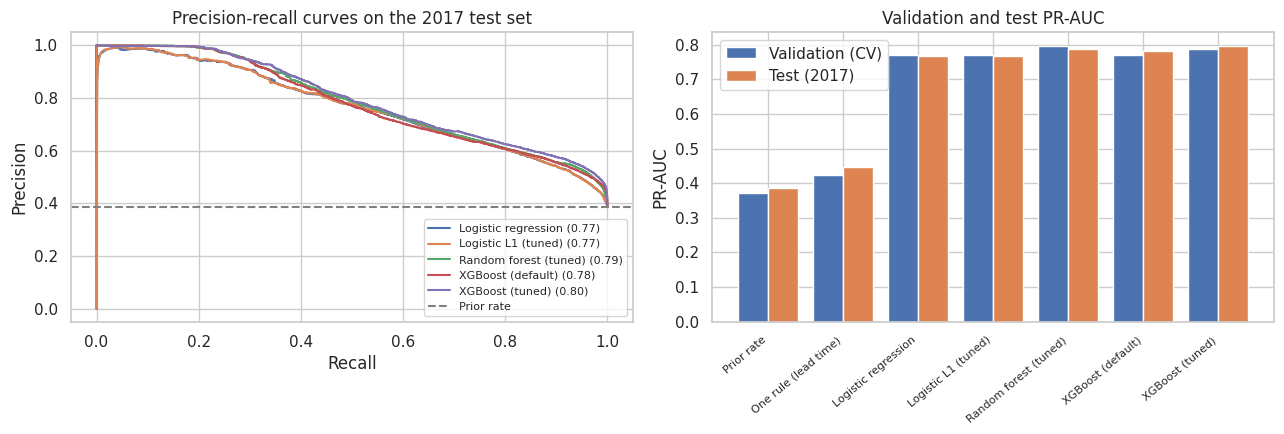

In [55]:
# Order of the models in the table.
order = ["Prior rate", "One rule (lead time)", "Logistic regression", "Logistic L1 (tuned)",
         "Random forest (tuned)", "XGBoost (default)", "XGBoost (tuned)"]
# Comparison table: validation score and test score for each model.
table = pd.DataFrame({
    "CV PR-AUC (2016 folds)": [np.mean(results[m]["cv_scores"]) for m in order],
    "CV Brier": [results[m].get("cv_brier", np.nan) for m in order],
    "Test PR-AUC (2017)": [results[m]["PR-AUC"] for m in order],
    "Test ROC-AUC": [results[m]["ROC-AUC"] for m in order],
    "Test F1": [results[m]["F1"] for m in order],
    "Test Brier": [results[m]["Brier"] for m in order],
}, index=order).round(3)
display(table)

# Left chart: precision-recall curves on the test set.
# Right chart: validation against test PR-AUC.
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for m in order[2:]:
    prec, rec, _ = precision_recall_curve(y_test, results[m]["p_test"])
    axes[0].plot(rec, prec, label=f"{m} ({results[m]['PR-AUC']:.2f})")
axes[0].axhline(y_test.mean(), color="grey", linestyle="--", label="Prior rate")
axes[0].set_xlabel("Recall"); axes[0].set_ylabel("Precision")
axes[0].set_title("Precision-recall curves on the 2017 test set"); axes[0].legend(fontsize=8)

# Bars side by side for validation and test.
x = np.arange(len(order)); w = 0.4
axes[1].bar(x - w / 2, table["CV PR-AUC (2016 folds)"], w, label="Validation (CV)")
axes[1].bar(x + w / 2, table["Test PR-AUC (2017)"], w, label="Test (2017)")
axes[1].set_xticks(x); axes[1].set_xticklabels(order, rotation=40, ha="right", fontsize=8)
axes[1].set_ylabel("PR-AUC"); axes[1].set_title("Validation and test PR-AUC"); axes[1].legend()
plt.tight_layout(); plt.show()

In [56]:
# PR-AUC of each model in each validation fold. It shows which season is hard.
fold_table = pd.DataFrame({m: results[m]["cv_scores"] for m in order[2:]},
                          index=["Fold 1 (Apr-Jun 2016)", "Fold 2 (Jul-Sep 2016)", "Fold 3 (Oct-Dec 2016)"]).round(3)
display(fold_table)

,Logistic regression,Logistic L1 (tuned),Random forest (tuned),XGBoost (default),XGBoost (tuned)
Fold 1 (Apr-Jun 2016),0.807,0.808,0.846,0.818,0.836
Fold 2 (Jul-Sep 2016),0.714,0.713,0.730,0.699,0.722
Fold 3 (Oct-Dec 2016),0.788,0.789,0.809,0.796,0.808


**What we see**

- All four real models are far above the baselines. The best ones reach a test PR-AUC of about 0.79 against 0.39 for no skill.
- Random forest is best on validation (0.795). XGBoost tuned is best on test PR-AUC (0.792) and has the best test Brier score (0.156). But the gaps between these two are small (less than 0.01), and much smaller than the difference between folds.
- The scores change a lot by fold. Fold 2 (July to September 2016) is the hardest for every model (about 0.70 to 0.73) and fold 1 is the easiest. So summer bookings are harder to predict. We see this again in the test months later.
- Validation and test scores are close to each other for all models, so we are not fooling ourselves with the tuning.

## Part 2, 9. Final model
We choose the final model using validation only: the highest mean PR-AUC over the three folds. We do not look at the test score for this choice. This gives **random forest**. XGBoost is very close and we are open about this. The random forest also has a slightly better validation Brier score (0.159 against 0.161).

The many small studies in the next sections need many refits. To keep the notebook fast, they use the tuned XGBoost, which is much quicker than the forest. Both models are close in score, so the answers should be the same in direction. The cost analysis, tiers and final pipeline use the final random forest.

In [57]:
# Choose the final model using validation PR-AUC only. We do not look at the test score.
main_models = ["Logistic regression", "Logistic L1 (tuned)", "Random forest (tuned)", "XGBoost (tuned)"]
final_name = max(main_models, key=lambda m: np.mean(results[m]["cv_scores"]))     # best validation PR-AUC
final = results[final_name]

print("Final model, chosen on validation PR-AUC:", final_name)
print("Validation PR-AUC:", round(np.mean(final["cv_scores"]), 3), "| Validation Brier:", round(final["cv_brier"], 3))
print("Threshold from validation (best F1):", round(final["thr"], 3))
print("Test PR-AUC:", round(final["PR-AUC"], 3), "| Test ROC-AUC:", round(final["ROC-AUC"], 3))

# the side studies below refit many models, so they use the tuned XGBoost (much faster than the forest)
# Keep the tuned XGBoost for the side studies.
xgb_result = results["XGBoost (tuned)"]
# best_model = XGBoost with the tuned settings (not trained yet).
best_model = clone(xgb_result["pipe"].named_steps["model"])
# set_A = the main feature set.
set_A = feature_sets["A strict"]

Final model, chosen on validation PR-AUC: Random forest (tuned)
Validation PR-AUC: 0.795 | Validation Brier: 0.159
Threshold from validation (best F1): 0.242
Test PR-AUC: 0.787 | Test ROC-AUC: 0.838


### How tuning helped, and why we picked the random forest

All tuning used the rolling validation folds, so a better score means the model did better on later months and not just on its own training data.

For XGBoost, the default settings gave a validation PR-AUC of 0.771 and a validation Brier score of 0.186. After tuning they became 0.788 and 0.161. On the 2017 test set, PR-AUC went from 0.781 to 0.792 and Brier from 0.161 to 0.156. Most of the gain is in better probabilities. The search chose shallow trees (depth 3) and a small learning rate (0.05), which stops the model from over-fitting the training months.

For the random forest, the search chose a max depth of 14, a minimum leaf size of 3 and 250 trees. It reached 0.795 on validation, against 0.770 for logistic regression. We did not run a default forest, so we can't say how much of this gain comes from tuning alone.

For L1 logistic regression, tuning C did not help (0.770 before and after), so the simple model is already at its limit.

We fixed the selection rule before looking at the test set: take the highest mean validation PR-AUC. Random forest got 0.795, tuned XGBoost 0.788 and logistic regression 0.770. The forest also has the lowest validation Brier score (0.159, against 0.161 for XGBoost and about 0.167 for logistic regression), so its probabilities are the most honest, which matters for the cost analysis. The gap to XGBoost is small, and on the 2017 test set XGBoost is slightly higher (0.792 against 0.787). We don't use the test set to choose, so we keep the forest. Either model would be a fair choice here.

## Part 2, 10. Question 1: how much does leakage inflate the score?
We run the same tuned model on all six feature sets. We pick the main set by timing logic, and these numbers only show the effect.

,columns,CV PR-AUC,Test PR-AUC,Test ROC-AUC
feature set,,,,
A strict,20,0.789,0.796,0.848
A without adr,19,0.783,0.790,0.843
A plus deposit,21,0.791,0.801,0.850
A paper-safe,14,0.697,0.725,0.783
B plus ambiguous,24,0.844,0.829,0.878
C leaky,26,1.000,1.000,1.000


Test PR-AUC gained by the leaky columns: 0.204


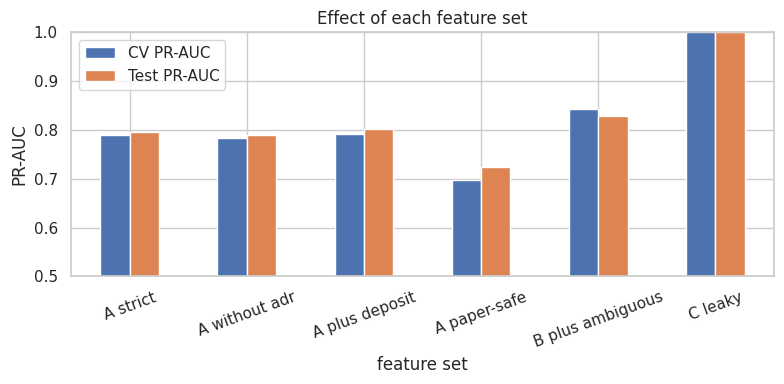

In [58]:
# Run the same model on all six feature sets.
rows = []
for name, fs in feature_sets.items():
    cols = columns_of(fs)
    # Build the pipeline, run rolling validation, then check on the test set.
    pipe = make_pipe(fs, clone(best_model))
    scores, _, _ = rolling_cv(pipe, cols)
    fitted = clone(pipe).fit(train_val[cols], y_tv)
    p = fitted.predict_proba(test[cols])[:, 1]
    rows.append([name, len(cols), np.mean(scores), average_precision_score(y_test, p), roc_auc_score(y_test, p)])

# Table of scores for each feature set.
ablation = pd.DataFrame(rows, columns=["feature set", "columns", "CV PR-AUC", "Test PR-AUC", "Test ROC-AUC"]).set_index("feature set").round(3)
display(ablation)

# How much score the leaky columns add (this is fake improvement).
drop_leaky = ablation.loc["C leaky", "Test PR-AUC"] - ablation.loc["A strict", "Test PR-AUC"]
print("Test PR-AUC gained by the leaky columns:", round(drop_leaky, 3))

# Bar chart of validation and test PR-AUC.
ablation[["CV PR-AUC", "Test PR-AUC"]].plot.bar(figsize=(8, 4), rot=20)
plt.ylim(0.5, 1.0); plt.ylabel("PR-AUC"); plt.title("Effect of each feature set"); plt.tight_layout(); plt.show()

**What we see**

- The leaky set C gives a perfect 1.000 score, because reservation status simply tells the answer. Compared to our strict set it adds 0.208 PR-AUC on the test set. So an honest model scores about 0.79, and a leaky one looks perfect but is useless in real life.
- The four ambiguous columns (set B) also raise the score: test PR-AUC 0.829 against 0.792. These columns can be filled after booking, such as special requests, so part of this gain may be future information. We keep them out of the main model.
- Deposit type adds only 0.004 (0.796 against 0.792). It looks very strong in the EDA, but country and market segment already carry most of that information. So we do not need to take the risk of using it.
- Removing ADR costs only 0.005, so the model does not depend on price.
- **A paper-safe** (without country, meal, guests, nights and weekend stay) gives a test PR-AUC of 0.724, which is 0.068 lower than set A (0.792). So part of our score comes from columns that the data paper says can change at check-in, and country is one of them. Even so, the model is far above no skill (0.387). Our honest range for a model at booking time is therefore about 0.72 to 0.79.

## Part 2, 11. Question 2: random split against split by time
A random split mixes old and new bookings, so the model sees the future during training. We compare it with the real setup (train on 2015 and 2016, test on 2017). The random test set has the same size as 2017, and we repeat with three seeds.

In [59]:
# random split with the same test size as 2017, repeated with 3 seeds
colsA_list = columns_of(set_A)
# Here we keep PR-AUC and ROC-AUC of each seed.
random_scores = []
for seed in [1, 2, 3]:
    # stratify keeps the same cancel rate in both parts.
    tr, te = train_test_split(df, test_size=len(test) / len(df), stratify=df["is_canceled"], random_state=seed)
    m = make_pipe(set_A, clone(best_model)).fit(tr[colsA_list], tr["is_canceled"])
    p = m.predict_proba(te[colsA_list])[:, 1]
    random_scores.append([average_precision_score(te["is_canceled"], p), roc_auc_score(te["is_canceled"], p)])
random_scores = np.array(random_scores)

# Compare random split with time split.
gap = pd.DataFrame({
    "PR-AUC": [random_scores[:, 0].mean(), xgb_result["PR-AUC"]],
    "ROC-AUC": [random_scores[:, 1].mean(), xgb_result["ROC-AUC"]],
}, index=["Random split (mean of 3)", "Chronological (train 2015-16, test 2017)"]).round(3)
display(gap)
print("PR-AUC gap:", round(gap["PR-AUC"].iloc[0] - gap["PR-AUC"].iloc[1], 3))
print("Random split PR-AUC for each seed:", random_scores[:, 0].round(3))

,PR-AUC,ROC-AUC
Random split (mean of 3),0.873,0.908
"Chronological (train 2015-16, test 2017)",0.796,0.848


PR-AUC gap: 0.077
Random split PR-AUC for each seed: [0.873 0.874 0.873]


A random split gives a PR-AUC of 0.841 against 0.792 for the split by time. So a random split looks about **0.049 better** than the truth (and ROC-AUC 0.885 against 0.848). All three seeds give almost the same number, so this is not luck. Part of the reason is that cancellation behaviour changes with time (we saw this in Part 1), and part is that duplicate rows land on both sides of a random split (checked in section 12). In a real hotel, the model always predicts the future, so the time split is the right number to report.

### Performance by test month
Here we look at the final model on each month of 2017. We use the same-month cancel rate as the no-skill line.

,bookings,cancel rate,PR-AUC,ROC-AUC
month (2017),,,,
January,3681,0.340,0.772,0.844
February,4177,0.325,0.749,0.839
March,4970,0.336,0.798,0.870
April,5661,0.435,0.843,0.862
May,6313,0.438,0.860,0.868
June,5647,0.432,0.830,0.840
July,5313,0.373,0.675,0.784
August,4925,0.369,0.608,0.757


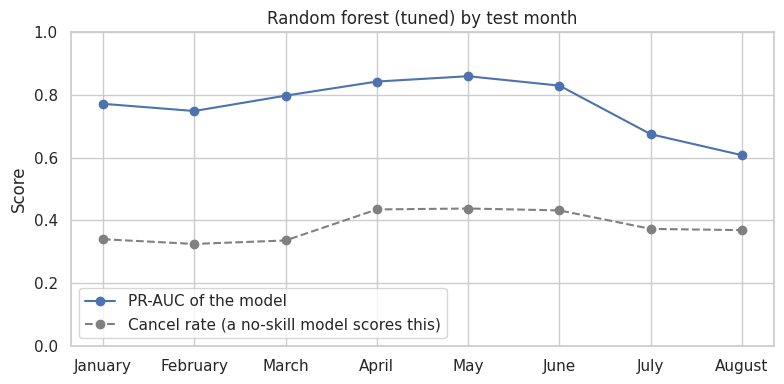

In [60]:
# Probabilities of the final model on the test set.
p_final = final["p_test"]
# Score of the model in each month of 2017.
rows = []
for month in month_order[:8]:
    mask = (test["arrival_date_month"] == month).values
    rows.append([month, mask.sum(), y_test[mask].mean(),
                 average_precision_score(y_test[mask], p_final[mask]),
                 roc_auc_score(y_test[mask], p_final[mask])])
monthly = pd.DataFrame(rows, columns=["month (2017)", "bookings", "cancel rate", "PR-AUC", "ROC-AUC"]).set_index("month (2017)").round(3)
display(monthly)

# Line chart: model score against the no-skill line for each month.
plt.figure(figsize=(8, 4))
plt.plot(monthly.index, monthly["PR-AUC"], marker="o", label="PR-AUC of the model")
plt.plot(monthly.index, monthly["cancel rate"], marker="o", linestyle="--", color="grey", label="Cancel rate (a no-skill model scores this)")
plt.ylim(0, 1); plt.ylabel("Score"); plt.title(f"{final_name} by test month"); plt.legend()
plt.tight_layout(); plt.show()

The model is best in April to June (PR-AUC 0.83 to 0.86) and weakest in July (0.675) and August (0.608), although the cancel rate in those months is not very different. This matches fold 2 in the validation, where summer was also the hardest. A possible reason is that summer cancellations follow different patterns from the rest of the year, so what the model learned from other months does not carry over fully. We did not test this, so it is only a guess. For the hotel, the practical advice is to trust the scores most in spring and be more careful in peak summer.

## Part 2, 12. Check with duplicate rows removed
In Part 1 we found that 26.8% of rows are exact duplicates, and we kept them. We promised to also report results without them. Here we keep one row for each exact pattern and repeat the time split and the random split.

In [61]:
# same check again with only one row for each exact pattern
# Remove duplicate rows. We keep one row for each exact pattern.
dedup = df[~df["is_duplicate"]]
rows = []
colsA_list = columns_of(set_A)

# Time split on the data without duplicates.
d_tv = dedup[dedup["arrival_date_year"] < 2017]
d_te = dedup[dedup["arrival_date_year"] == 2017]
# Train on 2015-2016 and test on 2017.
m = make_pipe(set_A, clone(best_model)).fit(d_tv[colsA_list], d_tv["is_canceled"])
p = m.predict_proba(d_te[colsA_list])[:, 1]
rows.append(["Chronological, no duplicates", len(d_tv), len(d_te), average_precision_score(d_te["is_canceled"], p), d_te["is_canceled"].mean()])

# Random split on the data without duplicates.
tr, te = train_test_split(dedup, test_size=len(d_te) / len(dedup), stratify=dedup["is_canceled"], random_state=1)
# Train on the random training part and test on the random test part.
m = make_pipe(set_A, clone(best_model)).fit(tr[colsA_list], tr["is_canceled"])
p = m.predict_proba(te[colsA_list])[:, 1]
rows.append(["Random split, no duplicates", len(tr), len(te), average_precision_score(te["is_canceled"], p), te["is_canceled"].mean()])

# Add the main result, for comparison.
rows.append(["Chronological, all rows", len(train_val), len(test), xgb_result["PR-AUC"], y_test.mean()])
# Show the three settings in one table.
display(pd.DataFrame(rows, columns=["setting", "train rows", "test rows", "PR-AUC", "test cancel rate"]).round(3))

,setting,train rows,test rows,PR-AUC,test cancel rate
0,"Chronological, no duplicates",55704,31692,0.614,0.319
1,"Random split, no duplicates",55704,31692,0.672,0.275
2,"Chronological, all rows",78703,40687,0.796,0.387


With duplicates removed the scores fall (0.607 for the time split), but the cancel rate also falls (0.319 against 0.387), so the no-skill line is lower too. Relative to the cancel rate the model is about 1.9 times better than no skill, against about 2.0 times with all rows. So duplicates do make the results look a bit better, but the model still has real skill. The random split is again better than the time split (0.645 against 0.607), so the gap from section 11 is not caused only by duplicates. The two test sets have different cancel rates, so these two numbers are not perfectly comparable.

## Part 2, 13. Question 3: cost and best threshold
A model score is only useful if it helps a decision. We imagine the hotel does something for a booking it thinks will cancel (calls the guest, asks for a deposit, or keeps a room ready to resell).

**Our assumptions.** We do not have real hotel costs, so these are guesses and the hotel should replace them:

- Acting on one booking costs **10 euros**.
- If the booking was going to cancel and we acted, we save **30%** of its value (ADR times nights).
- If we do nothing, we lose the full value of every cancelled booking.

We compare three policies on the 2017 test set: do nothing, act on every booking, and act when the model probability is above a threshold. The threshold is chosen on the validation predictions only, as the one that gives the lowest cost.

,bookings acted on,revenue lost,money spent,total cost,saving vs do nothing,saving %
policy,,,,,,
Do nothing (no model),0,7213169.2,0,7213169.2,0.0,0.0
Act on every booking,40687,5049218.4,406870,5456088.4,1757080.8,24.4
"Model, threshold 0.07",37368,5050564.1,373680,5424244.1,1788925.1,24.8


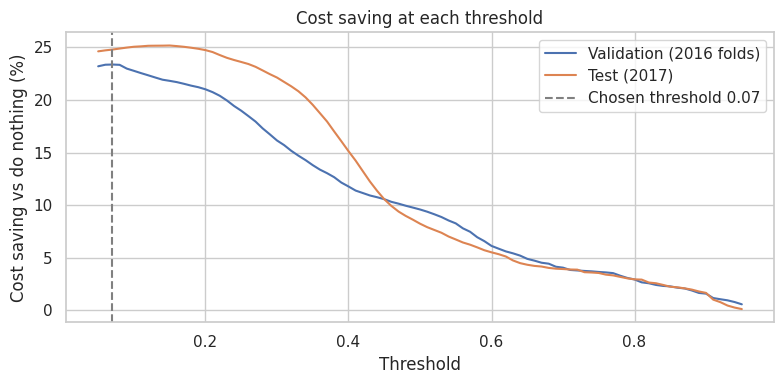

In [62]:
# Cost assumptions (hotel should replace these with its own numbers)
COST_PER_FLAG = 10      # euros spent on each booking we act on (reminder call, small offer, etc.)
RECOVERY = 0.30         # share of the booking value we save when we act on a booking that would cancel

# Total cost = revenue lost from cancellations + money spent on actions.
# flag = 1 means we act on that booking.
def total_cost(y, value, flag, c=COST_PER_FLAG, r=RECOVERY):
    # If we act, we save a part (RECOVERY) of the lost value.
    lost = (value * y * (1 - r * flag)).sum()      # revenue lost from cancellations
    return lost + c * flag.sum()                    # plus what we spent on acting

# Thresholds from 0.05 to 0.95 to try.
thresholds = np.round(np.arange(0.05, 0.96, 0.01), 2)

# Picks the threshold with the lowest cost on validation predictions.
def best_threshold(c=COST_PER_FLAG, r=RECOVERY):
    """Cheapest threshold on the validation predictions of the final model."""
    y = y_tv.iloc[final["oof_idx"]].values
    v = train_val["booking_value"].iloc[final["oof_idx"]].values
    costs = [total_cost(y, v, (final["oof_p"] >= t).astype(int), c, r) for t in thresholds]
    return thresholds[int(np.argmin(costs))]

# The chosen threshold.
t_star = best_threshold()
# Test set values: yt = real cancel, vt = booking value, pt = predicted probability.
yt, vt, pt = y_test.values, test["booking_value"].values, final["p_test"]

# Three policies to compare.
policies = {
    "Do nothing (no model)": np.zeros(len(test), dtype=int),
    "Act on every booking": np.ones(len(test), dtype=int),
    f"Model, threshold {t_star:.2f}": (pt >= t_star).astype(int),
}
rows = []
# Calculate lost money, spent money and total cost for each policy.
for name, flag in policies.items():
    lost = (vt * yt * (1 - RECOVERY * flag)).sum()
    spent = COST_PER_FLAG * flag.sum()
    rows.append([name, flag.sum(), lost, spent, lost + spent])
cost_table = pd.DataFrame(rows, columns=["policy", "bookings acted on", "revenue lost", "money spent", "total cost"]).set_index("policy")
# Saving compared with doing nothing.
cost_table["saving vs do nothing"] = cost_table.loc["Do nothing (no model)", "total cost"] - cost_table["total cost"]
cost_table["saving %"] = 100 * cost_table["saving vs do nothing"] / cost_table.loc["Do nothing (no model)", "total cost"]
display(cost_table.round(1).astype({"bookings acted on": int}))

# cost against threshold, on validation and on test
# Validation values (from the rolling folds).
y_v = y_tv.iloc[final["oof_idx"]].values
v_v = train_val["booking_value"].iloc[final["oof_idx"]].values
# Cost of doing nothing, on validation and on test.
base_v = total_cost(y_v, v_v, np.zeros(len(y_v), dtype=int))
base_t = total_cost(yt, vt, np.zeros(len(yt), dtype=int))
# Saving % at each threshold.
save_v = [100 * (base_v - total_cost(y_v, v_v, (final["oof_p"] >= t).astype(int))) / base_v for t in thresholds]
save_t = [100 * (base_t - total_cost(yt, vt, (pt >= t).astype(int))) / base_t for t in thresholds]
# Chart: saving at each threshold.
plt.plot(thresholds, save_v, label="Validation (2016 folds)")
plt.plot(thresholds, save_t, label="Test (2017)")
plt.axvline(t_star, color="grey", linestyle="--", label=f"Chosen threshold {t_star:.2f}")
plt.xlabel("Threshold"); plt.ylabel("Cost saving vs do nothing (%)"); plt.title("Cost saving at each threshold")
plt.legend(); plt.tight_layout(); plt.show()

Doing nothing loses about 7.2 million euros of booking value in 2017. Acting on every booking already saves 24.4%, because with these assumptions acting is cheap compared to the value of a booking. The model saves **24.8%**, which is a bit better, but only by about 32,000 euros. The chosen threshold is very low (0.07), so the model says "act" on 37,368 of the 40,687 bookings and only leaves the safest ones alone.

So with cheap actions the model adds little. The next table checks what happens when our guesses are wrong.

In [63]:
# what if our cost guesses are wrong? threshold is chosen again on validation each time
# Different action costs and recovery rates to test.
costs_list = [5, 10, 20, 40]
recover_list = [0.1, 0.2, 0.3, 0.5]
# Empty tables to fill. One for the model and one for acting on every booking.
model_save = pd.DataFrame(index=[f"cost {c}" for c in costs_list], columns=[f"recover {int(r*100)}%" for r in recover_list], dtype=float)
all_save = model_save.copy()
for c in costs_list:
    for r in recover_list:
        # Choose the threshold again for each pair, using validation only.
        t = best_threshold(c, r)
        base = total_cost(yt, vt, np.zeros(len(yt), dtype=int), c, r)
        model_cost = total_cost(yt, vt, (pt >= t).astype(int), c, r)
        all_cost = total_cost(yt, vt, np.ones(len(yt), dtype=int), c, r)
        model_save.loc[f"cost {c}", f"recover {int(r*100)}%"] = 100 * (base - model_cost) / base
        all_save.loc[f"cost {c}", f"recover {int(r*100)}%"] = 100 * (base - all_cost) / base
print("Saving of the model policy vs do nothing (%)")
display(model_save.round(1))
print("Saving of acting on every booking vs do nothing (%)")
display(all_save.round(1))

Saving of the model policy vs do nothing (%)


,recover 10%,recover 20%,recover 30%,recover 50%
cost 5,7.5,17.4,27.4,47.3
cost 10,5.7,14.9,24.8,44.7
cost 20,2.1,11.4,19.8,39.8
cost 40,-0.1,4.2,13.4,32.4


Saving of acting on every booking vs do nothing (%)


,recover 10%,recover 20%,recover 30%,recover 50%
cost 5,7.2,17.2,27.2,47.2
cost 10,4.4,14.4,24.4,44.4
cost 20,-1.3,8.7,18.7,38.7
cost 40,-12.6,-2.6,7.4,27.4


The model is never worse than doing nothing by more than 0.1%, while acting on every booking can lose money. At 40 euros per action and 10% recovery, acting on everyone loses 12.6%, while the model stays at about zero because it leaves the low-risk bookings alone. At 20 euros and 10% recovery, the model saves 2.1% and acting on everyone loses 1.3%. When the action is cheap and works well (top right), both are the same. So the value of the model is in **expensive or less effective actions**, where choosing the right bookings matters.

### Risk tiers
Kmiecik and Antonio (2026), our main related study, found that risk-based rules for low-risk guests work better than one strict rule for everybody. This is the idea behind risk tiers. For the hotel staff three risk tiers are also easier than a threshold. We fix the cut-offs in advance (0.30 and 0.60) and check what happens in each tier on the test set under our base assumptions.

In [64]:
# risk tiers with fixed cut-offs
# Low, Medium or High risk, using fixed cut-offs 0.30 and 0.60.
def risk_tier(p):
    return pd.cut(p, bins=[-0.01, 0.30, 0.60, 1.01], labels=["Low (below 0.30)", "Medium (0.30 to 0.60)", "High (0.60 and above)"])

# Put each test booking in a tier.
tier = risk_tier(pt)
rows = []
for name in tier.categories:
    mask = (tier == name)
    n = mask.sum()
    # Money saved if we act on the cancelled bookings of this tier.
    saved = (RECOVERY * vt[mask] * yt[mask]).sum()
    # Net gain = money saved - money spent.
    net = saved - COST_PER_FLAG * n
    rows.append([name, n, yt[mask].mean(), pt[mask].mean(), net, net / n])
tier_table = pd.DataFrame(rows, columns=["tier", "bookings", "actual cancel rate", "average predicted", "net gain if we act (euros)", "per booking"]).set_index("tier")
display(tier_table.round(2))

,bookings,actual cancel rate,average predicted,net gain if we act (euros),per booking
tier,,,,,
Low (below 0.30),18567,0.14,0.15,160281.67,8.63
Medium (0.30 to 0.60),17610,0.50,0.41,1200029.15,68.14
High (0.60 and above),4510,0.96,0.82,396769.94,87.98


- **Low (below 0.30):** 18,567 bookings, 14% really cancelled. Acting gives only a small gain (about 8.6 euros per booking). With a higher action cost, this tier is the first one to turn negative (for example it loses money at 40 euros).
- **Medium (0.30 to 0.60):** 17,610 bookings, 50% cancelled. This tier gives the largest total gain (about 1.2 million euros).
- **High (0.60 and above):** 4,510 bookings, 96% cancelled. Highest gain per booking (about 88 euros).

Recommendation: always act on High and Medium. Act on Low only if the action is very cheap.

The model's probabilities are a little low for the Medium and High tiers in 2017 (average predicted 0.41 and 0.82 against real 0.50 and 0.96). Cancellations went up in 2017, so the model slightly underestimates them. The ranking is still useful.

## Part 2, 14. More about the final model
The confusion matrix uses the cut-off found on validation (best F1). The calibration plot checks if a predicted 0.7 really means about 70% cancelled.

Precision: 0.562 | Recall: 0.891 | F1: 0.689


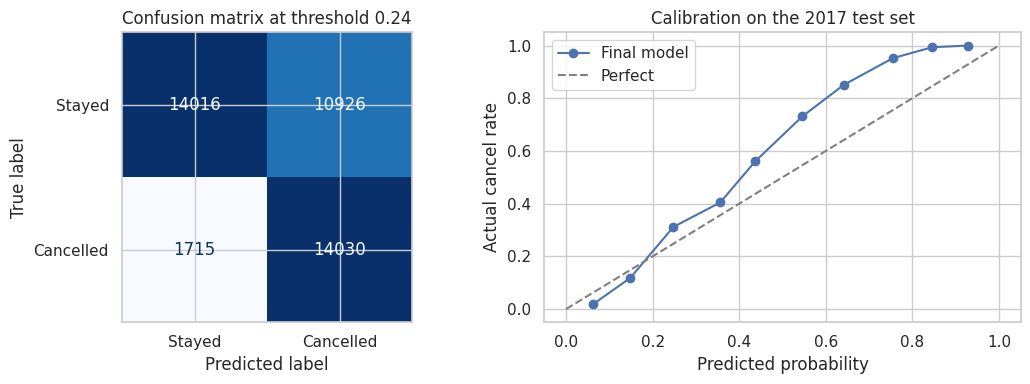

In [65]:
# Left: confusion matrix. Right: calibration plot.
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# Use the threshold found on validation (best F1).
flag = (pt >= final["thr"]).astype(int)
ConfusionMatrixDisplay.from_predictions(yt, flag, display_labels=["Stayed", "Cancelled"], cmap="Blues", ax=axes[0], colorbar=False)
axes[0].set_title(f"Confusion matrix at threshold {final['thr']:.2f}")
print("Precision:", round(precision_score(yt, flag), 3), "| Recall:", round(recall_score(yt, flag), 3), "| F1:", round(f1_score(yt, flag), 3))

# Calibration: predicted probability against real cancel rate, in 10 bins.
frac_pos, mean_pred = calibration_curve(yt, pt, n_bins=10)
axes[1].plot(mean_pred, frac_pos, marker="o", label="Final model")
# The grey dotted line is perfect calibration.
axes[1].plot([0, 1], [0, 1], linestyle="--", color="grey", label="Perfect")
axes[1].set_xlabel("Predicted probability"); axes[1].set_ylabel("Actual cancel rate")
axes[1].set_title("Calibration on the 2017 test set"); axes[1].legend()
plt.tight_layout(); plt.show()

At the F1 cut-off of 0.24 the model finds 89% of the cancellations (recall 0.891) but only 56% of the bookings it flags really cancel (precision 0.562). This is a good setting if missing a cancellation is more costly than a wasted action, which is what our cost analysis found. The calibration curve shows the same thing as the tier table: the probabilities are a bit low at the high end in 2017.

## Part 2, 15. Question 4: which factors matter?
**Importance by SHAP.** SHAP tells how much each column pushes the prediction up or down. We group the one-hot columns back to the original column. This is done for the tuned XGBoost on 5,000 test bookings.

,mean |SHAP|
country,1.000
lead_time,0.535
customer_type,0.476
market_segment,0.467
adr,0.191
previous_cancellations,0.185
hotel,0.154
arrival_date_month,0.099
previous_bookings_not_canceled,0.080
distribution_channel,0.068


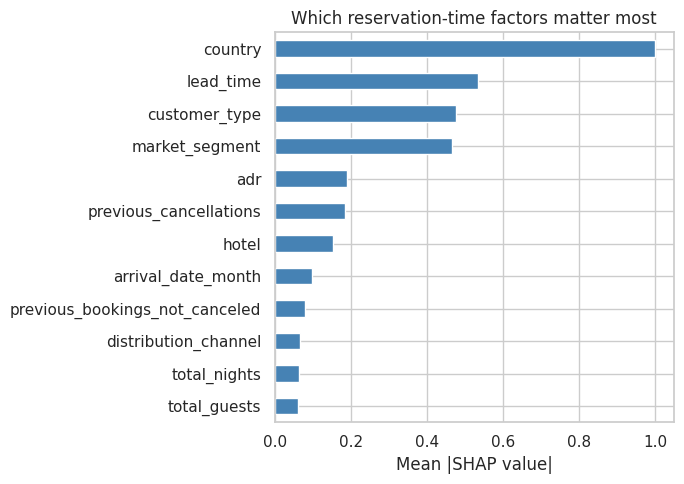

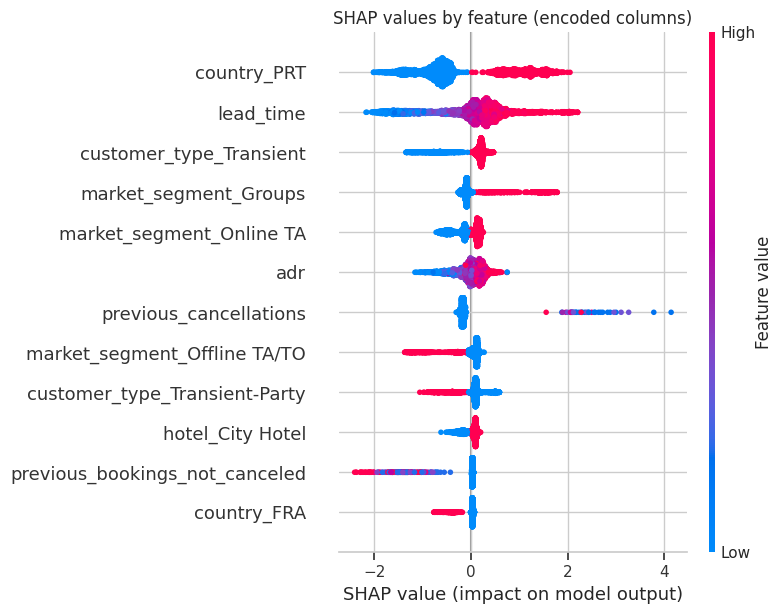

In [66]:
# SHAP values of the tuned XGBoost on a sample of the 2017 test set
# Take 5,000 random test bookings. SHAP on all rows would be slow.
sample = test.sample(5000, random_state=RANDOM_STATE)
xgb_pipe = xgb_result["pipe"]
# Get the preprocessing step and the final column names.
prep = xgb_pipe.named_steps["prep"]
# Transform the sample into model input.
Xs = prep.transform(sample[colsA])
names = prep.get_feature_names_out()

# SHAP values come directly from XGBoost. The last column is the base value.
contrib = xgb_pipe.named_steps["model"].get_booster().predict(DMatrix(Xs), pred_contribs=True)
shap_values = contrib[:, :-1]          # last column is the base value

# Changes a one-hot name (like country_PRT) back to the original column (country).
def original_name(feature):
    name = feature.split("__", 1)[1]
    for c in sorted(CAT, key=len, reverse=True):
        if name.startswith(c + "_"):
            return c
    return name

# Original column name for each encoded column.
groups = pd.Series([original_name(n) for n in names])
# Add the SHAP values of all one-hot columns which belong to the same original column.
grouped = pd.DataFrame({g: shap_values[:, (groups == g).values].sum(axis=1) for g in groups.unique()})
# Importance = average absolute SHAP value.
importance = grouped.abs().mean().sort_values(ascending=False)
display(importance.round(3).to_frame("mean |SHAP|").head(12))

# Bar chart of the top 12 factors.
plt.figure(figsize=(7, 5))
importance.head(12)[::-1].plot.barh(color="steelblue")
plt.xlabel("Mean |SHAP value|"); plt.title("Which reservation-time factors matter most")
plt.tight_layout(); plt.show()

# SHAP summary plot. Each dot is one booking. The colour shows a low or high value.
shap.summary_plot(shap_values, Xs, feature_names=[n.split("__", 1)[1] for n in names], max_display=12, show=False)
plt.title("SHAP values by feature (encoded columns)")
plt.tight_layout(); plt.show()

Country is the most important factor, then lead time, customer type and market segment. After these, previous cancellations, hotel and ADR matter less. The data paper says the real country is often known only at check-in, so the importance of country should be read with care (see the paper-safe result in section 10). From the EDA in Part 1 the direction is: Portuguese guests, group bookings, transient customers and long lead times go with more cancellations. These are associations only, not causes. In Part 1 we also saw that country, group segment and non-refund deposits overlap, so country is probably standing in for a particular type of Portuguese group or agent booking.

**Are the factors stable over time?** We train two models, one on the earlier months (July 2015 to March 2016) and one on the later months (April to December 2016). We then shuffle each column on the 2017 test data and see how much the score drops.

Rank correlation between the two periods: 0.88


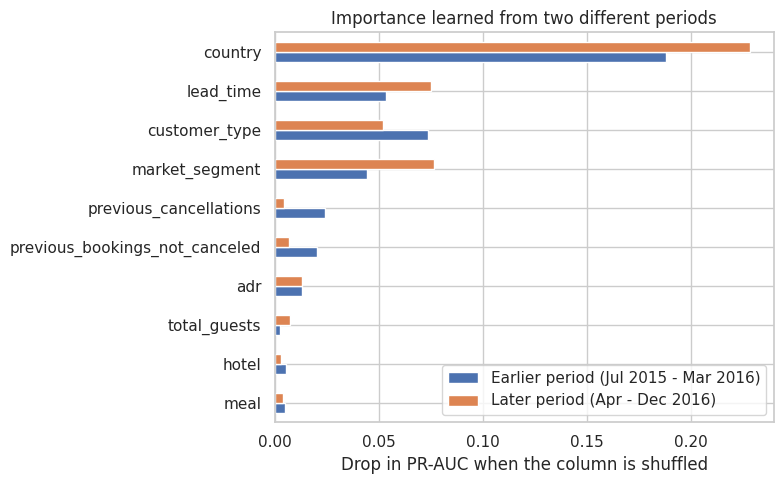

,Earlier period (Jul 2015 - Mar 2016),Later period (Apr - Dec 2016)
country,1,1
lead_time,3,3
customer_type,2,4
market_segment,4,2
previous_cancellations,5,8
previous_bookings_not_canceled,6,7
adr,7,5
total_guests,12,6
hotel,8,10
meal,9,9


In [67]:
# does the model learn the same factors from an earlier and a later period?
# Two training periods: the earlier part and the later part of 2015-2016.
early = train_val[train_val["arrival_date"] < "2016-04-01"]
late = train_val[train_val["arrival_date"] >= "2016-04-01"]
# Same 8,000 test bookings for both models.
eval_sample = test.sample(8000, random_state=RANDOM_STATE)

imp = {}
# Train one model on each period.
for label, part in [("Earlier period (Jul 2015 - Mar 2016)", early), ("Later period (Apr - Dec 2016)", late)]:
    m = make_pipe(set_A, clone(best_model)).fit(part[colsA], part["is_canceled"])
    # Permutation importance: shuffle one column and see how much PR-AUC drops.
    r = permutation_importance(m, eval_sample[colsA], eval_sample["is_canceled"],
                               scoring="average_precision", n_repeats=3, random_state=RANDOM_STATE)
    imp[label] = pd.Series(r.importances_mean, index=colsA)
# Put the two importance lists in one table.
imp = pd.DataFrame(imp)

# Spearman correlation of the two rankings. Close to 1 means the same order.
rank_corr = imp.rank().corr(method="spearman").iloc[0, 1]
print("Rank correlation between the two periods:", round(rank_corr, 2))
# Top 10 columns.
top = imp.sum(axis=1).sort_values(ascending=False).head(10).index
imp.loc[top][::-1].plot.barh(figsize=(8, 5))
plt.xlabel("Drop in PR-AUC when the column is shuffled"); plt.title("Importance learned from two different periods")
plt.tight_layout(); plt.show()
# Rank of each column in each period (1 = most important).
display(imp.rank(ascending=False).loc[top].astype(int))

The rank correlation between the two periods is 0.84, which is high. Country is first in both periods, and customer type and market segment stay in the top four in both. Lead time moves a little (4th and 2nd), and smaller columns like hotel, ADR and total nights move more. So the main risk factors are quite stable, and mostly the smaller ones change.

**Does a model move from one hotel to the other?** We train on one hotel (2015 and 2016) and test on each hotel's 2017 bookings. The two hotels have different cancel rates, so we also show lift, which is PR-AUC divided by the cancel rate.

In [68]:
# train on one hotel, test on the other (2017 bookings)
# Remove the hotel column, because each model sees only one hotel.
cat_no_hotel = [c for c in CAT if c != "hotel"]
fs_hotel = dict(num=NUM, bin=BIN, cat=cat_no_hotel)
cols_hotel = columns_of(fs_hotel)

rows = []
# Train on one hotel.
for train_hotel in ["City Hotel", "Resort Hotel"]:
    tr = train_val[train_val["hotel"] == train_hotel]
    m = make_pipe(fs_hotel, clone(best_model)).fit(tr[cols_hotel], tr["is_canceled"])
    # Test on both hotels (2017 bookings).
    for test_hotel in ["City Hotel", "Resort Hotel"]:
        te = test[test["hotel"] == test_hotel]
        p = m.predict_proba(te[cols_hotel])[:, 1]
        # Lift = PR-AUC divided by cancel rate. It is fair when cancel rates are different.
        pr = average_precision_score(te["is_canceled"], p)
        rows.append([train_hotel, test_hotel, "same hotel" if train_hotel == test_hotel else "other hotel",
                     pr, te["is_canceled"].mean(), pr / te["is_canceled"].mean(), roc_auc_score(te["is_canceled"], p)])
transfer = pd.DataFrame(rows, columns=["trained on", "tested on", "type", "PR-AUC", "cancel rate", "lift over cancel rate", "ROC-AUC"]).round(3)
display(transfer)

,trained on,tested on,type,PR-AUC,cancel rate,lift over cancel rate,ROC-AUC
0,City Hotel,City Hotel,same hotel,0.822,0.425,1.934,0.847
1,City Hotel,Resort Hotel,other hotel,0.648,0.308,2.107,0.810
2,Resort Hotel,City Hotel,other hotel,0.764,0.425,1.797,0.791
3,Resort Hotel,Resort Hotel,same hotel,0.671,0.308,2.183,0.819


Raw PR-AUC falls a little when the model moves to the other hotel (City model on Resort: about 0.65 against 0.69 for the Resort's own model; Resort model on City: about 0.78 against 0.82 for the City's own model). Part of this is only because the hotels have different cancel rates (0.425 and 0.308). The lift is a fairer view: City to Resort is about 2.1 (own model about 2.3) and Resort to City is about 1.8 (own model about 1.9). So a model trained on one hotel still works well on the other, with a small loss, but a model trained on the same hotel is a little better.

## Part 2, 16. Final pipeline
The final pipeline is: preprocessing, then the tuned random forest, using only the strict reservation-time features of set A. For the real use, we refit it on all the data from 2015 to 2017 and save it. The test results in this notebook come from the model trained on 2015 and 2016 only.

`score_bookings` takes new bookings and gives a cancel probability and a risk tier. The demo below uses the 2015 and 2016 model on 8 test bookings, so the result is honest.

In [69]:
# final pipeline: refit on all data (2015 to 2017) so that new bookings are scored by the most recent model
# Columns of the main set A.
all_cols = columns_of(set_A)
deploy_pipe = make_pipe(set_A, clone(final["pipe"].named_steps["model"])).fit(df[all_cols], df["is_canceled"])
# Save the model in a file, for later use.
joblib.dump(deploy_pipe, "hotel_cancellation_model.joblib")

# Takes new bookings and gives a cancel probability and a risk tier.
def score_bookings(bookings, pipe=deploy_pipe):
    """Takes bookings in the same format as the cleaned data and returns cancel probability and risk tier."""
    out = pd.DataFrame(index=bookings.index)
    out["cancel_probability"] = pipe.predict_proba(bookings[all_cols])[:, 1].round(3)
    out["risk_tier"] = risk_tier(out["cancel_probability"].values)
    return out

# quick demo on 8 bookings from the test set (scored with the 2015-2016 model, so the result is honest)
demo = test.sample(8, random_state=3)
scored = score_bookings(demo, final["pipe"])
scored["hotel"] = demo["hotel"]; scored["lead_time"] = demo["lead_time"]; scored["market_segment"] = demo["market_segment"]
scored["actually_cancelled"] = demo["is_canceled"]
display(scored)

,cancel_probability,risk_tier,hotel,lead_time,market_segment,actually_cancelled
17323,0.359,Medium (0.30 to 0.60),City Hotel,109,Online TA,1
5364,0.345,Medium (0.30 to 0.60),Resort Hotel,40,Groups,0
4194,0.712,High (0.60 and above),Resort Hotel,45,Direct,1
13862,0.384,Medium (0.30 to 0.60),City Hotel,10,Online TA,1
33057,0.173,Low (below 0.30),City Hotel,82,Direct,0
16850,0.354,Medium (0.30 to 0.60),City Hotel,190,Online TA,1
29872,0.099,Low (below 0.30),City Hotel,206,Groups,0
15535,0.439,Medium (0.30 to 0.60),City Hotel,241,Online TA,1


### One new booking through the pipeline
The earlier demo used bookings from the test set. Here we make one completely new booking (a City Hotel booking for September 2017, which is not in the data). `prepare_booking` builds the same extra columns as the cleaning step. Then the saved model file is loaded and `score_bookings` gives the probability and the risk tier.

In [70]:
# one brand new booking, as it would be entered when the reservation is made
new_booking = {
    "hotel": "City Hotel", "arrival_date": "2017-09-12", "lead_time": 150, "adr": 95.0,
    "stays_in_weekend_nights": 0, "stays_in_week_nights": 3,
    "adults": 2, "children": 0, "babies": 0,
    "meal": "BB", "country": "PRT", "market_segment": "Online TA", "distribution_channel": "TA/TO",
    "reserved_room_type": "A", "customer_type": "Transient",
    "is_repeated_guest": 0, "previous_cancellations": 0, "previous_bookings_not_canceled": 0,
    "agent": 9, "company": 0,
}

# Builds the same extra columns as the cleaning step. The model needs them.
def prepare_booking(b):
    """Builds the same extra columns that we made in the cleaning step."""
    # Make a one-row table from the dictionary.
    d = pd.DataFrame([b])
    arrival = pd.to_datetime(d["arrival_date"])
    d["arrival_date_month"] = arrival.dt.month_name()
    d["arrival_weekday"] = arrival.dt.day_name()
    d["total_nights"] = d["stays_in_week_nights"] + d["stays_in_weekend_nights"]
    d["total_guests"] = d["adults"] + d["children"] + d["babies"]
    d["is_family"] = ((d["children"] > 0) | (d["babies"] > 0)).astype(int)
    d["weekend_stay"] = (d["stays_in_weekend_nights"] > 0).astype(int)
    d["has_agent"] = (d["agent"] > 0).astype(int)
    d["has_company"] = (d["company"] > 0).astype(int)
    return d

# load the saved pipeline from the file, to show that the file works on its own
saved_pipe = joblib.load("hotel_cancellation_model.joblib")

# Prepare the booking, then get the probability.
new_df = prepare_booking(new_booking)
answer = score_bookings(new_df, saved_pipe).iloc[0]
tier = str(answer["risk_tier"])

# Simple advice from the risk tier.
if tier.startswith("Low"):
    action = "No action needed (act only if the action is very cheap)."
else:
    action = "Act on this booking (call the guest, ask for a deposit, or plan to resell the room)."

# Show the result.
print("New booking: City Hotel, Online TA, Portugal, 3 nights, lead time 150 days")
print("Predicted cancellation probability:", answer["cancel_probability"])
print("Risk tier:", tier)
print("Suggested action:", action)

New booking: City Hotel, Online TA, Portugal, 3 nights, lead time 150 days
Predicted cancellation probability: 0.581
Risk tier: Medium (0.30 to 0.60)
Suggested action: Act on this booking (call the guest, ask for a deposit, or plan to resell the room).


## Part 2, 17. Final results and answers

In [71]:
# Final summary table of the main results.
summary = pd.DataFrame({
    "Result": [final_name,
               round(np.mean(final["cv_scores"]), 3),
               round(final["PR-AUC"], 3),
               round(final["ROC-AUC"], 3),
               round(final["Brier"], 3),
               round(y_test.mean(), 3),
               round(float(cost_table.iloc[2]["saving %"]), 1)]
}, index=["Final model", "Validation PR-AUC (CV)", "Test PR-AUC (2017)", "Test ROC-AUC", "Test Brier score",
          "Test cancel rate (PR-AUC of a model with no skill)", "Cost saving vs do nothing (%)"])
display(summary)

,Result
Final model,Random forest (tuned)
Validation PR-AUC (CV),0.795
Test PR-AUC (2017),0.787
Test ROC-AUC,0.838
Test Brier score,0.164
Test cancel rate (PR-AUC of a model with no skill),0.387
Cost saving vs do nothing (%),24.8


**Answers to our research questions**

1. **Leakage.** With only reservation-time columns, the test PR-AUC is about 0.79. When reservation status and assigned room type are added, it becomes a perfect 1.000, so the leaked columns add 0.21 of fake performance. The columns that may be filled in after booking (set B) also add a little (0.04), so we keep them out. If we also remove the columns that the data paper warns about (country, meal, guests, nights), the score is 0.724, which is still far above no skill (0.387).
2. **Random split against time split.** A random split overstates PR-AUC by about 0.049 (0.841 against 0.792). Performance also changes by month: it is strongest in April to June (up to 0.86) and weakest in July and August (0.61 to 0.68).
3. **Cost.** Under our assumed costs, the model saves 24.8% of the cancellation loss compared with doing nothing. Acting on every booking saves 24.4%, so the model is only a little better when actions are cheap. It is clearly better and safer when actions are costly or work less well. The hotel should put in its own cost numbers.
4. **Risk factors.** Country, lead time, customer type and market segment matter most, and their order is stable between the earlier and later periods (rank correlation 0.84). A model trained on one hotel works on the other with a small loss in lift.

**Final model:** random forest on strict reservation-time features, with validation PR-AUC 0.795, test PR-AUC 0.787 and test ROC-AUC 0.838.

**Limits we should be honest about**

- The data comes from two hotels in Portugal between 2015 and 2017, so it may not fit other places or years.
- The cost numbers are our own assumptions, not real hotel numbers.
- Duplicate rows are kept in the main results. The duplicate check gives a lower score, so the real skill is a bit lower than the headline.
- The side studies and SHAP use XGBoost and not the final forest, to save time.
- We looked at the test set in the side studies (leakage, hotel transfer and so on), but we never used it to choose the final model, the feature set or the threshold.
- Country, meal, guests and nights may be corrected at check-in (data paper), so the headline score of 0.79 may be a little high for a real booking-time model. The paper-safe score of 0.72 is the low end.
- The cancellation rate went up in 2017 and the model's probabilities are slightly low. In real use the model should be retrained from time to time.
- SHAP and the EDA show associations. They do not prove that a factor causes cancellation.

**References**

- Antonio, N., Almeida, A. d., & Nunes, L. (2019). Hotel booking demand datasets. Data in Brief, 22, 41-49.
- Gaudreault, J. G., & Branco, P. (2024). Empirical analysis of performance assessment for imbalanced classification. Machine Learning, 113, 5533-5575.
- Kmiecik, M., & Antonio, N. (2026). Cancel, rebook, save: Revenue leakage from price cuts in hotels. International Journal of Hospitality Management, 135.

## Part 2, 18. Example prediction
This shows the saved final pipeline on bookings it has never seen. Each booking uses only information known at reservation time (feature set A). For each one we show the cancel probability and risk tier, plus what the hotel would gain by acting, using the same cost assumptions as Section 13 (10 euros per action, 30% of the booking value recovered).

In [72]:
# Load the saved final pipeline from its file, as a real user would
saved_pipe = joblib.load("hotel_cancellation_model.joblib")

def make_booking(**changes):
    """Starts from the booking used in Section 16 and changes only the fields we ask for."""
    base = {
        "hotel": "City Hotel", "arrival_date": "2017-09-12", "lead_time": 150, "adr": 95.0,
        "stays_in_weekend_nights": 0, "stays_in_week_nights": 3,
        "adults": 2, "children": 0, "babies": 0,
        "meal": "BB", "country": "PRT", "market_segment": "Online TA", "distribution_channel": "TA/TO",
        "reserved_room_type": "A", "customer_type": "Transient",
        "is_repeated_guest": 0, "previous_cancellations": 0, "previous_bookings_not_canceled": 0,
        "agent": 9, "company": 0,
    }
    base.update(changes)
    return base

def predict_one(booking, pipe=saved_pipe):
    """Returns probability, tier, booking value, expected loss and expected net gain of acting."""
    scored = score_bookings(prepare_booking(booking), pipe).iloc[0]
    p = float(scored["cancel_probability"])
    nights = booking["stays_in_week_nights"] + booking["stays_in_weekend_nights"]
    value = booking["adr"] * nights                              # same definition as booking_value
    expected_loss = p * value                                    # money at risk if we do nothing
    net_gain = RECOVERY * p * value - COST_PER_FLAG              # expected saving minus cost of acting
    return p, str(scored["risk_tier"]), value, expected_loss, net_gain

scenarios = {
    "1. Section 16 booking (Online TA, Portugal, 150 days ahead)": make_booking(),
    "2. Likely safe (repeat guest, Direct, UK, 5 days ahead)": make_booking(
        lead_time=5, market_segment="Direct", distribution_channel="Direct", country="GBR",
        is_repeated_guest=1, previous_bookings_not_canceled=2, agent=0),
    "3. Likely risky (group, Portugal, 250 days ahead, earlier cancellation)": make_booking(
        lead_time=250, market_segment="Groups", customer_type="Transient-Party",
        country="PRT", previous_cancellations=1),
}

rows = []
for name, b in scenarios.items():
    p, tier, value, exp_loss, net = predict_one(b)
    action = "No action needed (act only if very cheap)" if tier.startswith("Low") else "Act: call guest, ask for deposit or plan to resell"
    rows.append([name, p, tier, round(value, 1), round(exp_loss, 1), round(net, 1), action])

example_table = pd.DataFrame(rows, columns=["booking", "cancel probability", "risk tier", "booking value (euros)",
                                             "expected loss (euros)", "expected net gain of acting (euros)",
                                             "suggested action"]).set_index("booking")
display(example_table)

,cancel probability,risk tier,booking value (euros),expected loss (euros),expected net gain of acting (euros),suggested action
booking,,,,,,
"1. Section 16 booking (Online TA, Portugal, 150 days ahead)",0.581,Medium (0.30 to 0.60),285.0,165.6,39.7,"Act: call guest, ask for deposit or plan to resell"
"2. Likely safe (repeat guest, Direct, UK, 5 days ahead)",0.075,Low (below 0.30),285.0,21.4,-3.6,No action needed (act only if very cheap)
"3. Likely risky (group, Portugal, 250 days ahead, earlier cancellation)",0.901,High (0.60 and above),285.0,256.8,67.0,"Act: call guest, ask for deposit or plan to resell"


,cancel probability,change vs original
change,,
Original booking,0.581,0.000
Books 7 days ahead instead of 150,0.315,-0.266
Books 300 days ahead,0.620,0.039
Direct booking instead of Online TA,0.309,-0.272
Guest from the UK instead of Portugal,0.370,-0.211
Repeat guest,0.317,-0.264
Earlier cancellation on record,0.875,0.294


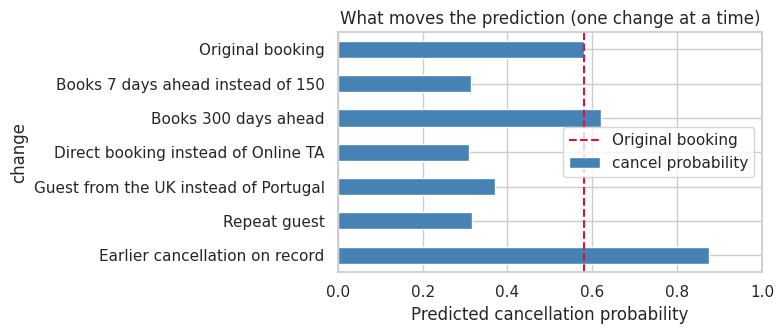

In [73]:
base = make_booking()
p0 = predict_one(base)[0]

what_if = {
    "Books 7 days ahead instead of 150": dict(lead_time=7),
    "Books 300 days ahead": dict(lead_time=300),
    "Direct booking instead of Online TA": dict(market_segment="Direct", distribution_channel="Direct"),
    "Guest from the UK instead of Portugal": dict(country="GBR"),
    "Repeat guest": dict(is_repeated_guest=1, previous_bookings_not_canceled=2),
    "Earlier cancellation on record": dict(previous_cancellations=1),
}

rows = [["Original booking", p0, 0.0]]
for label, change in what_if.items():
    p = predict_one(make_booking(**change))[0]
    rows.append([label, p, round(p - p0, 3)])

what_if_table = pd.DataFrame(rows, columns=["change", "cancel probability", "change vs original"]).set_index("change")
display(what_if_table)

ax = what_if_table["cancel probability"].plot.barh(figsize=(8, 3.5), color="steelblue")
ax.axvline(p0, color="crimson", linestyle="--", label="Original booking")
ax.set_xlabel("Predicted cancellation probability")
ax.set_xlim(0, 1)
ax.invert_yaxis()
ax.legend()
plt.title("What moves the prediction (one change at a time)")
plt.tight_layout()
plt.show()



| Booking | Cancel probability | Risk tier | Expected net gain of acting | Action |
|---|---|---|---|---|
| Online TA, Portugal, 150 days ahead | 0.581 | Medium | +39.7 euros | Act |
| Repeat guest, Direct, UK, 5 days ahead | 0.075 | Low | -3.6 euros | No action |
| Group, Portugal, 250 days ahead, earlier cancellation | 0.901 | High | +67.0 euros | Act |

The three bookings have the same value (285 euros), so the difference in expected gain comes only from the predicted probability. The pipeline separates the safe booking from the risky one, and the tiers lead to the actions recommended in Section 13. The safe booking has a negative net gain because its probability (0.075) is below the break-even probability for a 285-euro booking (10 / (0.3 x 285) = 0.117). Acting on it would cost more than the expected saving.

**What moves the prediction.** Changing one field at a time on the first booking (0.581): booking 7 days ahead instead of 150 lowers the probability to 0.315, a Direct booking to 0.309, a guest from the UK to 0.370, and a repeat guest to 0.317. An earlier cancellation on record raises it to 0.875, which moves the booking into the High tier. Booking 300 days ahead instead of 150 adds only 0.039. Lead time, market segment, country and guest history move the score most, which matches the Part 1 analysis and the factor ranking in Question 4. "Direct" changes both the segment and the channel, and "repeat guest" changes the flag and the previous-bookings count, so those two rows show combined effects.